# Lab 1 - Środowisko, tensory i gradient od podstaw (TensorFlow i PyTorch)

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne, 2025/2026)
**Prowadząca:** dr inż. Natalia Piórkowska
**Czas:** 180 min (Google Colab, GPU T4)
**Treści programowe:** T1 (wprowadzenie, parametry i hiperparametry), T2 (biblioteki TensorFlow i PyTorch - instalacja, konfiguracja, podstawowe operacje)

## Cel zajęć
Po tych zajęciach będziesz umieć samodzielnie uruchomić środowisko do uczenia głębokiego, posługiwać się tensorami w **TensorFlow** i **PyTorch**, liczyć gradienty automatycznie (autograd) i - co najważniejsze - **rozumieć, co się dzieje "pod maską" uczenia**: zaimplementujesz spadek gradientu od zera, zobaczysz, jak hiperparametry (learning rate, liczba epok, rozmiar batcha, pojemność modelu) wpływają na wynik, i zaobserwujesz przeuczenie.

Wszystko, co zrobimy dziś na regresji liniowej, jest dokładnie tym samym mechanizmem, który trenuje sieci z milionami parametrów - zmienia się tylko model i skala.

## Efekty uczenia (z karty przedmiotu)
- **UGŁ_W01** - zna metody uczenia sieci (spadek gradientu, funkcja straty, optymalizacja).
- **UGŁ_W02** - zna narzędzia DL (TensorFlow/Keras, PyTorch, GPU) i ich rolę w cyklu życia modelu.
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "zbyt duży learning rate spowoduje rozbieżność") eksperymentalnie.
- **UGŁ_U02** - korzysta z istniejących bibliotek (autograd zamiast ręcznych pochodnych).
- **UGŁ_K01** - rozumie potrzebę korzystania z aktualnej dokumentacji (keras.io, pytorch.org).

## Powiązanie z wykładem
- **W1** - paradygmat: dane, model, funkcja straty, optymalizator; minimalizacja ryzyka empirycznego; spadek gradientu i learning rate; parametry vs hiperparametry; train/val/test; overfitting i underfitting.
- **W2** - tensory, urządzenia GPU, graf obliczeniowy i backpropagation (reguła łańcuchowa, autograd), ekosystem TF/Keras i PyTorch.

## Harmonogram (180 min)
| Czas | Część |
|---|---|
| 0-10 min | Wprowadzenie, uruchomienie Colab + GPU (sekcja 0) |
| 10-40 min | 1. Tensory w NumPy, TensorFlow i PyTorch (Zadania 1.1-1.2) |
| 40-65 min | 2. Automatyczne różniczkowanie (Zadania 2.1-2.2) |
| 65-75 min | **Przerwa** |
| 75-110 min | 3. Regresja liniowa od zera: NumPy, PyTorch, TensorFlow (Zadania 3.1-3.2) |
| 110-130 min | 4. Learning rate i liczba epok (Zadanie 4.1) |
| 130-150 min | 5. Mini-batch vs full-batch (Zadanie 5.1) |
| 150-175 min | 6. Regresja wielomianowa i przeuczenie (Zadania 6.1-6.2) |
| 175-180 min | Pytania kontrolne, podsumowanie |

## Wymagania wstępne
- Python na poziomie podstawowym (funkcje, pętle, listy, słowniki) - por. Lutz, "Python. Wprowadzenie".
- Podstawy NumPy (tablice, indeksowanie) - jeśli ich nie znasz, sekcja 1 je przypomni.
- Matematyka: pochodna funkcji jednej zmiennej, pochodna cząstkowa, mnożenie macierzy.
- Konto Google (Colab).

> **Jak pracować z notebookiem?** Uruchamiaj komórki po kolei (Shift+Enter). Komórki z `# TODO` uzupełniasz samodzielnie - polecenie i kryteria sukcesu są w komórce markdown tuż nad nimi. Jeśli coś przestanie działać, użyj *Środowisko wykonawcze -> Uruchom ponownie i uruchom wszystko*.

## 0. Przygotowanie środowiska

### 0.1 Włączenie GPU w Google Colab
1. Menu **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego**.
2. W polu *Akcelerator sprzętowy* wybierz **T4 GPU** i kliknij *Zapisz*.
3. Uruchom komórki poniżej. Jeśli GPU nie jest dostępne (np. wyczerpany limit darmowego Colab), notebook też zadziała na CPU - wtedy ustaw `SZYBKI_TRYB = True` (patrz niżej).

Colab ma domyślnie zainstalowane TensorFlow (z Keras 3), PyTorch, scikit-learn, NumPy, pandas i matplotlib - **nie instalujemy niczego przez `pip`**.

Polecenie `!nvidia-smi` (wykrzyknik = polecenie powłoki systemu) pokazuje kartę graficzną, sterownik i zajętą pamięć.

In [1]:
!nvidia-smi 2>/dev/null || echo "brak GPU"

brak GPU


### 0.2 Importy, konfiguracja i tryb szybki

Zmienna `SZYBKI_TRYB`:
- `False` (domyślnie) - pełne eksperymenty: więcej danych i epok, wyniki takie jak w opisie zadań.
- `True` - jeśli pracujesz **bez GPU** lub na słabym komputerze: zmniejszamy liczbę epok i rozmiar danych (np. do pierwszych 2000 próbek). Wnioski jakościowe pozostają te same, liczby będą gorsze.

Tryb można przełączyć zmienną środowiskową `DL_FAST=1` albo po prostu odkomentowując linię `SZYBKI_TRYB = True`.

**Ważne przy pracy z dwiema bibliotekami naraz:** TensorFlow domyślnie rezerwuje *całą* pamięć GPU przy pierwszej operacji. Wtedy PyTorch nie ma już miejsca i zgłasza błąd `CUDA out of memory`. Dlatego od razu po imporcie włączamy w TF tryb `memory_growth` (TF bierze pamięć tylko wtedy, gdy jej potrzebuje).

In [2]:
import os, time, math
import numpy as np
import matplotlib.pyplot as plt

# Cisza dla logow TF o braku GPU (CPU-only); nie zmienia dzialania
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")
_devnull = os.open(os.devnull, os.O_WRONLY)
_stderr_backup = os.dup(2)
os.dup2(_devnull, 2)
try:
    import tensorflow as tf
finally:
    import sys
    sys.stderr.flush()
    os.dup2(_stderr_backup, 2)
    os.close(_devnull); os.close(_stderr_backup)
# TF ma zajmować pamięć GPU stopniowo - inaczej PyTorch nie dostanie pamięci
for _gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(_gpu, True)

import torch
import keras

# Tryb szybki: True = mniej danych i epok (praca bez GPU)
# SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
SZYBKI_TRYB = True   # <- pracujesz bez GPU

print("SZYBKI_TRYB =", SZYBKI_TRYB)
print("NumPy      :", np.__version__)
print("TensorFlow :", tf.__version__, "| Keras:", keras.__version__)
print("PyTorch    :", torch.__version__)

SZYBKI_TRYB = True
NumPy      : 2.2.6
TensorFlow : 2.21.0 | Keras: 3.12.4
PyTorch    : 2.14.1+cpu


### 0.3 Sprawdzenie GPU i ustawienie ziaren losowości (seedów)

Każda biblioteka ma **własny** generator liczb losowych - żeby wyniki były powtarzalne, ustawiamy ziarno w każdej z nich (NumPy, TensorFlow, PyTorch). `keras.utils.set_random_seed` ustawia jednocześnie seedy Pythona, NumPy i backendu Keras.

Uwaga: pełna powtarzalność na GPU nie jest gwarantowana (niektóre operacje cuDNN są niedeterministyczne) - różnice rzędu 1e-6 są normalne. O powtarzalności wyników będzie więcej na W4.

In [3]:
SEED = 42
keras.utils.set_random_seed(SEED)   # Python random + NumPy + TF
np.random.seed(SEED)
torch.manual_seed(SEED)

# Urządzenie dla PyTorch: GPU jeśli jest, w przeciwnym razie CPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("GPU widziane przez TensorFlow:", tf.config.list_physical_devices("GPU"))
print("CUDA dostępna w PyTorch      :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Karta:", torch.cuda.get_device_name(0))
print("DEVICE =", DEVICE)

GPU widziane przez TensorFlow: []
CUDA dostępna w PyTorch      : False
DEVICE = cpu


## 1. Tensory: NumPy -> TensorFlow -> PyTorch

### 1.1 Czym jest tensor?
**Tensor** to wielowymiarowa tablica liczb jednego typu. W uczeniu głębokim wszystko jest tensorem: dane wejściowe, wagi, gradienty, wyjścia sieci.

| Rząd (`ndim`) | Nazwa | Przykład w DL | Typowy kształt |
|---|---|---|---|
| 0 | skalar | wartość straty | `()` |
| 1 | wektor | bias warstwy | `(64,)` |
| 2 | macierz | batch danych tabelarycznych, wagi warstwy gęstej | `(batch, cechy)` |
| 3 | tensor 3D | batch sekwencji / tekst | `(batch, czas, cechy)` |
| 4 | tensor 4D | batch obrazów | TF: `(N, H, W, C)`, PyTorch: `(N, C, H, W)` |

Trzy najważniejsze atrybuty każdego tensora: **kształt** (`shape`), **typ** (`dtype`) i **urządzenie** (CPU/GPU). Większość błędów w kodzie DL to niezgodność jednego z nich.

Tensory w TF i PyTorch różnią się od tablic NumPy dwiema rzeczami: (1) mogą żyć na **GPU**, (2) potrafią **śledzić operacje**, żeby liczyć gradienty (sekcja 2). API jest celowo bardzo podobne do NumPy.

In [4]:
# Zwykła tablica NumPy
a = np.array([[1., 2., 3.],
              [4., 5., 6.]])
print("NumPy :", a.shape, a.dtype, "ndim =", a.ndim)

# To samo w TensorFlow i PyTorch
a_tf = tf.constant(a)
a_pt = torch.tensor(a)
print("TF    :", a_tf.shape, a_tf.dtype)
print("Torch :", a_pt.shape, a_pt.dtype)

NumPy : (2, 3) float64 ndim = 2
TF    : (2, 3) <dtype: 'float64'>
Torch : torch.Size([2, 3]) torch.float64


**Zwróć uwagę na `dtype`.** NumPy domyślnie tworzy `float64`, a sieci neuronowe pracują prawie zawsze na `float32` (GPU są dla niego zoptymalizowane, a `float64` zużywa 2x więcej pamięci). Konwersja z NumPy "dziedziczy" `float64`, co prowadzi do typowych błędów:
- w PyTorch: `RuntimeError: mat1 and mat2 must have the same dtype` (wagi warstwy są `float32`, dane `float64`),
- w TF: `InvalidArgumentError: cannot compute MatMul as input #1 was expected to be a double tensor but is a float tensor`.

Dobry nawyk: **jawnie konwertuj dane do `float32`**.

In [5]:
# Jawne rzutowanie na float32 - dobry nawyk
a_tf32 = tf.convert_to_tensor(a, dtype=tf.float32)
a_pt32 = torch.tensor(a, dtype=torch.float32)
print(a_tf32.dtype, a_pt32.dtype)

# Powrót do NumPy
print(type(a_tf32.numpy()), type(a_pt32.numpy()))

# Pułapka: torch.from_numpy NIE kopiuje danych - tensor i tablica współdzielą pamięć
b = np.zeros(3)
b_pt = torch.from_numpy(b)
b[0] = 99.0                     # zmieniamy tablicę NumPy...
print("tensor po zmianie tablicy:", b_pt)   # ...i zmienia się tensor!

<dtype: 'float32'> torch.float32
<class 'numpy.ndarray'> <class 'numpy.ndarray'>
tensor po zmianie tablicy: tensor([99.,  0.,  0.], dtype=torch.float64)


### 1.2 Tworzenie tensorów
Obie biblioteki mają odpowiedniki funkcji NumPy: zera, jedynki, zakresy, liczby losowe. Różnica koncepcyjna: w TensorFlow `tf.constant` jest **niezmienny** (immutable) - do przechowywania parametrów modelu służy `tf.Variable`, który można modyfikować metodami `assign`, `assign_add`, `assign_sub`. W PyTorch każdy tensor jest zmienny, a operacje "w miejscu" mają podkreślnik na końcu (`add_`, `zero_`).

In [6]:
# Zera, jedynki, zakres, losowe - w obu bibliotekach
print(tf.zeros((2, 3)).numpy(), "\n", torch.zeros(2, 3))
print(tf.range(0, 10, 2).numpy(), torch.arange(0, 10, 2))
print(tf.random.normal((2, 2), seed=1).numpy())
print(torch.randn(2, 2))

# tf.Variable - modyfikowalny tensor (parametry modelu)
v = tf.Variable([1.0, 2.0, 3.0])
v.assign_add([1.0, 1.0, 1.0])       # v = v + 1
print("tf.Variable po assign_add:", v.numpy())

# PyTorch - operacja w miejscu (in-place) z podkreślnikiem
t = torch.tensor([1.0, 2.0, 3.0])
t.add_(1.0)
print("torch po add_:", t)

[[0. 0. 0.]
 [0. 0. 0.]] 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])
[0 2 4 6 8] tensor([0, 2, 4, 6, 8])
[[-1.499947   -1.2420495 ]
 [ 0.52283144 -0.35879248]]
tensor([[0.3367, 0.1288],
        [0.2345, 0.2303]])
tf.Variable po assign_add: [2. 3. 4.]
torch po add_: tensor([2., 3., 4.])


### 1.3 Indeksowanie, zmiana kształtu, transpozycja
- Indeksowanie i wycinki (`x[0]`, `x[:, 1:3]`) działają jak w NumPy.
- `reshape` zmienia kształt bez zmiany danych; `-1` oznacza "wylicz ten wymiar sam". Liczba elementów musi się zgadzać.
- Zmiana kolejności osi: w TF `tf.transpose(x, perm=[...])`, w PyTorch `x.permute(...)`.

**Najważniejsza różnica konwencji:** obrazy w TF/Keras mają format **NHWC** (kanały na końcu), w PyTorch **NCHW** (kanały po batchu). Przy przenoszeniu kodu lub wag między bibliotekami trzeba permutować osie - to bardzo częste źródło "cichych" błędów (kod działa, ale model uczy się bzdur).

In [7]:
x = np.arange(24, dtype=np.float32)
x_tf = tf.reshape(tf.constant(x), (2, 3, 4))     # 2*3*4 = 24 elementy
x_pt = torch.from_numpy(x).reshape(2, 3, 4)
print("kształt:", x_tf.shape, tuple(x_pt.shape))
print("element [1, 2, 3]:", x_tf[1, 2, 3].numpy(), x_pt[1, 2, 3].item())
print("wycinek [:, 0, :2]:\n", x_pt[:, 0, :2])

# -1: biblioteka sama wylicza wymiar
print(tf.reshape(x_tf, (4, -1)).shape, x_pt.reshape(-1, 6).shape)

# Batch obrazów: TF (N, H, W, C) -> PyTorch (N, C, H, W)
obrazy_nhwc = np.random.rand(8, 28, 28, 3).astype(np.float32)
obrazy_nchw = torch.from_numpy(obrazy_nhwc).permute(0, 3, 1, 2)
print("NHWC:", obrazy_nhwc.shape, "-> NCHW:", tuple(obrazy_nchw.shape))
# Ta sama operacja w TF
print("TF transpose:", tf.transpose(obrazy_nhwc, perm=[0, 3, 1, 2]).shape)

kształt: (2, 3, 4) (2, 3, 4)
element [1, 2, 3]: 23.0 23.0
wycinek [:, 0, :2]:
 tensor([[ 0.,  1.],
        [12., 13.]])
(4, 6) torch.Size([4, 6])
NHWC: (8, 28, 28, 3) -> NCHW: (8, 3, 28, 28)
TF transpose: (8, 3, 28, 28)


### 1.4 Broadcasting (rozgłaszanie)
Operacje elementowe (`+`, `-`, `*`, `/`) na tensorach o różnych kształtach są możliwe dzięki **broadcastingowi**. Reguła (identyczna w NumPy, TF i PyTorch):
1. Porównujemy kształty **od prawej strony**.
2. Dwa wymiary są zgodne, jeśli są **równe** albo jeden z nich wynosi **1** (wtedy jest "rozciągany").
3. Brakujące wymiary z lewej traktujemy jak 1.

Przykłady: `(3, 1) + (1, 4) -> (3, 4)`; `(64, 10) + (10,) -> (64, 10)` (dodanie biasu do każdej próbki w batchu!); `(3,) + (4,)` -> **błąd**.

Broadcasting jest wszechobecny w DL: dodawanie biasu, normalizacja cech (odejmowanie średniej), maski. Bywa też źródłem cichych błędów - np. `y` o kształcie `(n,)` i `y_pred` o kształcie `(n, 1)` dają po odjęciu macierz `(n, n)` zamiast wektora błędów! Zawsze sprawdzaj `shape`.

In [8]:
kol = np.array([[1.], [2.], [3.]])     # (3, 1)
wiersz = np.array([[10., 20., 30., 40.]])   # (1, 4)
print("(3,1) + (1,4) ->", (kol + wiersz).shape)
print(torch.tensor(kol) + torch.tensor(wiersz))

# Bias dodawany do każdej próbki w batchu
batch = tf.ones((5, 3))
bias = tf.constant([0.1, 0.2, 0.3])
print("(5,3) + (3,) ->", (batch + bias).shape)

# Klasyczny cichy błąd: (n,) - (n,1) daje macierz (n, n)!
y = np.array([1., 2., 3.])
y_pred = np.array([[1.1], [1.9], [3.2]])
print("Zły kształt błędu:", (y - y_pred).shape, " <- powinno być (3,)")
print("Poprawnie       :", (y - y_pred.ravel()).shape)

# Niezgodne kształty - wyjątek
try:
    torch.ones(3) + torch.ones(4)
except RuntimeError as e:
    print("Błąd broadcastingu:", str(e)[:80])

(3,1) + (1,4) -> (3, 4)
tensor([[11., 21., 31., 41.],
        [12., 22., 32., 42.],
        [13., 23., 33., 43.]], dtype=torch.float64)
(5,3) + (3,) -> (5, 3)
Zły kształt błędu: (3, 3)  <- powinno być (3,)
Poprawnie       : (3,)
Błąd broadcastingu: The size of tensor a (3) must match the size of tensor b (4) at non-singleton di


### 1.5 Mnożenie macierzy i operacje redukujące
- `*` - mnożenie **elementowe** (Hadamard), kształty muszą być zgodne wg broadcastingu.
- `@` lub `tf.matmul` / `torch.matmul` - **mnożenie macierzowe**: $(n \times k) \cdot (k \times m) = (n \times m)$. To serce warstwy gęstej: $\mathbf{Y} = \mathbf{X}\mathbf{W} + \mathbf{b}$, gdzie $\mathbf{X}$ ma kształt `(batch, wejścia)`, a $\mathbf{W}$ - `(wejścia, wyjścia)`.
- Dla tensorów 3D `matmul` wykonuje **mnożenie wsadowe** (osobno dla każdego elementu batcha).
- Redukcje: `sum`, `mean`, `max` po wskazanej osi (`axis` w NumPy/TF, `dim` w PyTorch). `keepdims=True` (`keepdim=True` w PyTorch) zachowuje wymiar o długości 1 - przydatne do późniejszego broadcastingu.

In [9]:
X = np.random.rand(4, 3).astype(np.float32)    # batch 4 próbek, 3 cechy
W = np.random.rand(3, 2).astype(np.float32)    # wagi: 3 wejścia -> 2 wyjścia

Y_np = X @ W
Y_tf = tf.matmul(X, W)
Y_pt = torch.from_numpy(X) @ torch.from_numpy(W)
print("kształt wyniku:", Y_np.shape)
print("zgodne:", np.allclose(Y_np, Y_tf.numpy()), np.allclose(Y_np, Y_pt.numpy()))

# Mnożenie wsadowe: 10 par macierzy (2x3)(3x5) naraz
A = torch.randn(10, 2, 3); B = torch.randn(10, 3, 5)
print("batch matmul:", (A @ B).shape)

# Redukcje z zachowaniem wymiaru
M = torch.arange(6.).reshape(2, 3)
print("suma po wierszach:", M.sum(dim=1), "| keepdim:", M.sum(dim=1, keepdim=True).shape)
print("TF mean po kolumnach:", tf.reduce_mean(tf.constant(M.numpy()), axis=0).numpy())

kształt wyniku: (4, 2)
zgodne: True True
batch matmul: torch.Size([10, 2, 5])
suma po wierszach: tensor([ 3., 12.]) | keepdim: torch.Size([2, 1])
TF mean po kolumnach: [1.5 2.5 3.5]


### Zadanie 1.1 - Standaryzacja batcha obrazów (broadcasting, NHWC vs NCHW)
W tablicy `batch_np` masz 16 "obrazów" RGB 32x32 w formacie **NHWC** (jak w Keras). Każdy kanał ma inną średnią i odchylenie.

Wykonaj **standaryzację per kanał**: $z = (x - \mu_c)/\sigma_c$, gdzie $\mu_c$ i $\sigma_c$ liczysz po wszystkich obrazach i pikselach danego kanału (osie N, H, W).
1. W **TensorFlow**: zamień `batch_np` na tensor, policz średnią i odchylenie (`tf.reduce_mean`, `tf.math.reduce_std`, z `keepdims=True` - jaki kształt mają statystyki?), zapisz wynik w `z_tf` (format NHWC).
2. W **PyTorch**: zamień batch na format **NCHW** (`permute`), policz statystyki po osiach `(0, 2, 3)` (`mean`, `std` z `correction=0`, `keepdim=True`), zapisz wynik w `z_pt` (format NCHW).

**Kryteria sukcesu:** w komórce sprawdzającej średnie per kanał ≈ 0, odchylenia ≈ 1, a wyniki TF i PyTorch (po przywróceniu kolejności osi) są zgodne (`True`).

**Wskazówki:** statystyki w TF powinny mieć kształt `(1, 1, 1, 3)`, w PyTorch `(1, 3, 1, 1)`. `std` w PyTorch domyślnie liczy odchylenie nieobciążone (dzieli przez $n-1$), TF - obciążone (przez $n$); `correction=0` ujednolica wynik.

In [10]:
rng = np.random.default_rng(0)
batch_np = rng.normal(loc=[0.5, 0.2, -0.3], scale=[2.0, 0.5, 1.0],
                      size=(16, 32, 32, 3)).astype(np.float32)

# standaryzacja w TF (z_tf, NHWC)
batch_tf = tf.constant(batch_np, dtype=tf.float32)
mu_tf = tf.reduce_mean(batch_tf, axis=[0, 1, 2], keepdims=True)
sigma_tf = tf.math.reduce_std(batch_tf, axis=[0, 1, 2], keepdims=True)
z_tf = (batch_tf - mu_tf) / sigma_tf

# standaryzacja w PyTorch (z_pt, NCHW)
batch_pt = torch.from_numpy(batch_np).permute(0, 3, 1, 2)
mu_pt = batch_pt.mean(dim=(0, 2, 3), keepdim=True)
sigma_pt = batch_pt.std(dim=(0, 2, 3), keepdim=True, correction=0)
z_pt = (batch_pt - mu_pt) / sigma_pt

In [11]:
# Komórka sprawdzająca - nie zmieniaj
if z_tf is None or z_pt is None:
    print("Uzupełnij z_tf i z_pt.")
else:
    print("TF  średnie per kanał:", np.round(tf.reduce_mean(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("TF  std per kanał    :", np.round(tf.math.reduce_std(z_tf, axis=[0, 1, 2]).numpy(), 4))
    print("PT  średnie per kanał:", np.round(z_pt.mean(dim=(0, 2, 3)).numpy(), 4))
    z_pt_nhwc = z_pt.permute(0, 2, 3, 1).numpy()      # powrót do NHWC
    print("Zgodność TF vs PyTorch:", np.allclose(z_tf.numpy(), z_pt_nhwc, atol=1e-5))

TF  średnie per kanał: [ 0. -0. -0.]
TF  std per kanał    : [1. 1. 1.]
PT  średnie per kanał: [0. 0. 0.]
Zgodność TF vs PyTorch: True


### Zadanie 1.2 - Macierz odległości bez pętli (wektoryzacja)
Pętle Pythona są bardzo wolne; w DL zawsze myślimy "całymi tensorami". Klasyczny przykład: macierz kwadratów odległości euklidesowych między wierszami $X \in \mathbb{R}^{n \times d}$ a $Y \in \mathbb{R}^{m \times d}$:
$$D_{ij} = \|x_i - y_j\|^2 = \|x_i\|^2 + \|y_j\|^2 - 2\, x_i^\top y_j .$$
W postaci macierzowej: kolumna norm $X$ (kształt `(n, 1)`) + wiersz norm $Y$ (kształt `(1, m)`) $- 2XY^\top$ - czyli broadcasting + jedno mnożenie macierzy.

1. Zaimplementuj `pairwise_sq_dist_np(X, Y)` w NumPy i `pairwise_sq_dist_torch(X, Y)` w PyTorch (bez pętli!).
2. Przez błędy zaokrągleń niektóre wartości mogą wyjść minimalnie ujemne - przytnij je do 0 (`np.maximum`, `torch.clamp`).

**Kryteria sukcesu:** komórka sprawdzająca wypisuje `zgodność z wersją pętlową: True` dla obu funkcji, a wersja wektorowa jest o rzędy wielkości szybsza od pętli.

**Wskazówka:** `(X**2).sum(axis=1)[:, None]` ma kształt `(n, 1)`. W PyTorch zamiast `[:, None]` możesz użyć `.unsqueeze(1)`.

In [12]:
def pairwise_sq_dist_np(X, Y):
    # normy^2 jako kolumna i wiersz
    x2 = (X ** 2).sum(axis=1)[:, None]
    y2 = (Y ** 2).sum(axis=1)[None, :]
    # minus 2 X Y^T
    D = x2 + y2 - 2 * X @ Y.T
    # przycięcie do 0
    return np.maximum(D, 0)


def pairwise_sq_dist_torch(X, Y):
    # to samo w PyTorch
    x2 = (X ** 2).sum(dim=1).unsqueeze(1)
    y2 = (Y ** 2).sum(dim=1).unsqueeze(0)
    D = x2 + y2 - 2 * X @ Y.T
    return torch.clamp(D, min=0)

In [13]:
# Komórka sprawdzająca - wersja pętlowa jako wzorzec
def pairwise_sq_dist_loop(X, Y):
    D = np.zeros((len(X), len(Y)))
    for i in range(len(X)):
        for j in range(len(Y)):
            D[i, j] = np.sum((X[i] - Y[j]) ** 2)
    return D

Xs, Ys = np.random.rand(50, 8), np.random.rand(40, 8)
D_ref = pairwise_sq_dist_loop(Xs, Ys)
D_np = pairwise_sq_dist_np(Xs, Ys)
D_pt = pairwise_sq_dist_torch(torch.from_numpy(Xs), torch.from_numpy(Ys))
if D_np is not None and D_pt is not None:
    print("NumPy - zgodność z wersją pętlową:", np.allclose(D_ref, D_np))
    print("Torch - zgodność z wersją pętlową:", np.allclose(D_ref, D_pt.numpy()))

    # Pomiar czasu: pętla vs wektoryzacja
    n_big = 150 if SZYBKI_TRYB else 400
    Xb, Yb = np.random.rand(n_big, 32), np.random.rand(n_big, 32)
    t0 = time.perf_counter(); pairwise_sq_dist_loop(Xb, Yb); t_loop = time.perf_counter() - t0
    t0 = time.perf_counter(); pairwise_sq_dist_np(Xb, Yb); t_vec = time.perf_counter() - t0
    print(f"n = {n_big}: pętla {t_loop:.3f} s, wektorowo {t_vec:.5f} s, przyspieszenie ~{t_loop / max(t_vec, 1e-9):.0f}x")

NumPy - zgodność z wersją pętlową: True
Torch - zgodność z wersją pętlową: True
n = 150: pętla 0.120 s, wektorowo 0.00614 s, przyspieszenie ~20x


### 1.6 Urządzenia: CPU vs GPU
Tensor "mieszka" na konkretnym urządzeniu. Operacje są wykonywane tam, gdzie leżą dane, a **wszystkie argumenty operacji muszą być na tym samym urządzeniu** (inaczej PyTorch zgłasza `Expected all tensors to be on the same device`).
- PyTorch: jawnie - `x.to(DEVICE)`, `x.cuda()`, `x.cpu()`; atrybut `x.device`.
- TensorFlow: automatycznie - jeśli jest GPU, operacje trafiają na GPU; można wymusić `with tf.device("/CPU:0"):`.

**Pomiar czasu na GPU - pułapka:** obliczenia CUDA są **asynchroniczne** - Python dostaje sterowanie z powrotem, zanim GPU skończy liczyć. Bez `torch.cuda.synchronize()` zmierzysz tylko czas "zlecenia" operacji. Podobnie pierwsze wywołanie jest wolniejsze (rozgrzewka: inicjalizacja kontekstu CUDA, wybór algorytmu) - dlatego mierzymy po rozgrzewce.

Poniżej porównujemy czas mnożenia dużych macierzy na CPU i GPU.

In [14]:
N = 512 if SZYBKI_TRYB else 4096          # rozmiar macierzy N x N
A_cpu = torch.randn(N, N)
B_cpu = torch.randn(N, N)

t0 = time.perf_counter(); C = A_cpu @ B_cpu; t_cpu = time.perf_counter() - t0
print(f"PyTorch CPU: {t_cpu * 1000:.1f} ms  (N = {N})")

if torch.cuda.is_available():
    A_gpu, B_gpu = A_cpu.to(DEVICE), B_cpu.to(DEVICE)   # kopiowanie na GPU
    _ = A_gpu @ B_gpu; torch.cuda.synchronize()         # rozgrzewka
    t0 = time.perf_counter()
    C_gpu = A_gpu @ B_gpu
    torch.cuda.synchronize()                            # czekamy na koniec obliczeń GPU
    t_gpu = time.perf_counter() - t0
    print(f"PyTorch GPU: {t_gpu * 1000:.1f} ms  -> przyspieszenie ~{t_cpu / t_gpu:.0f}x")
    print("Urządzenie wyniku:", C_gpu.device)
    print("Maks. różnica CPU vs GPU:", (C_gpu.cpu() - C).abs().max().item())
else:
    print("Brak GPU - pomijam porównanie (to nie błąd).")

# TensorFlow: wymuszenie urządzenia kontekstem
with tf.device("/CPU:0"):
    t0 = time.perf_counter(); _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy(); t_tf_cpu = time.perf_counter() - t0
print(f"TF CPU: {t_tf_cpu * 1000:.1f} ms")
if tf.config.list_physical_devices("GPU"):
    with tf.device("/GPU:0"):
        _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy()          # rozgrzewka
        t0 = time.perf_counter(); _ = tf.matmul(A_cpu.numpy(), B_cpu.numpy()).numpy(); t_tf_gpu = time.perf_counter() - t0
    print(f"TF GPU: {t_tf_gpu * 1000:.1f} ms (łącznie z kopiowaniem danych na GPU i z powrotem)")

PyTorch CPU: 9.6 ms  (N = 512)
Brak GPU - pomijam porównanie (to nie błąd).
TF CPU: 14.2 ms


## 2. Automatyczne różniczkowanie (autograd)

### 2.1 Po co nam gradienty?
Uczenie sieci to minimalizacja funkcji straty $L(\boldsymbol\theta)$ względem parametrów $\boldsymbol\theta$ (W1). Spadek gradientu wymaga wektora pochodnych cząstkowych $\nabla_{\boldsymbol\theta} L$. Liczenie ich ręcznie dla sieci z milionami parametrów jest niewykonalne - robi to za nas **autograd**.

### 2.2 Graf obliczeniowy i reguła łańcuchowa (W2)
Każde wyrażenie to złożenie prostych operacji. Np. $f(x) = \sin(x^2)$ to $u = x^2$, $f = \sin(u)$. Biblioteka zapamiętuje te operacje jako **graf obliczeniowy**, a potem stosuje **regułę łańcuchową**:
$$\frac{df}{dx} = \frac{df}{du}\cdot\frac{du}{dx} = \cos(x^2)\cdot 2x.$$
Przejście od wyniku do wejść (od końca grafu) to **tryb odwrotny** (reverse mode) = **backpropagation**. Jest bardzo wydajny, gdy wyjście jest jedno (skalarna strata), a wejść (parametrów) bardzo dużo - dokładnie przypadek DL: koszt policzenia całego gradientu to ok. 2-3 koszty jednego przejścia w przód.

### 2.3 Jak to wygląda w kodzie
- **TensorFlow:** operacje wykonane wewnątrz `with tf.GradientTape() as tape:` są "nagrywane"; `tape.gradient(y, x)` zwraca $\partial y/\partial x$. Domyślnie śledzone są tylko `tf.Variable` - zwykły tensor trzeba wskazać `tape.watch(x)`.
- **PyTorch:** tensor z `requires_grad=True` śledzi operacje; `y.backward()` liczy gradienty i **zapisuje je w atrybucie `x.grad`**.

Przykład: $f(x) = x^3 + 2x$, $f'(x) = 3x^2 + 2$, więc $f'(2) = 14$.

In [15]:
# --- TensorFlow ---
x = tf.Variable(2.0)
with tf.GradientTape() as tape:
    y = x ** 3 + 2 * x            # operacje są nagrywane na "taśmę"
dy_dx_tf = tape.gradient(y, x)
print("TF     f'(2) =", dy_dx_tf.numpy())

# --- PyTorch ---
x = torch.tensor(2.0, requires_grad=True)
y = x ** 3 + 2 * x                # graf budowany "w locie"
y.backward()                       # backpropagation
print("PyTorch f'(2) =", x.grad.item())

print("Analitycznie  =", 3 * 2.0 ** 2 + 2)

TF     f'(2) = 14.0
PyTorch f'(2) = 14.0
Analitycznie  = 14.0


### 2.4 Gradient na całej siatce punktów i porównanie z pochodną analityczną
Autograd liczy gradient **skalara**. Jeśli chcemy pochodną funkcji elementowej w wielu punktach naraz, sumujemy wyniki: $\frac{\partial}{\partial x_i}\sum_j f(x_j) = f'(x_i)$, bo każdy składnik zależy tylko od "swojego" $x_j$.

Funkcja testowa: $f(x) = x^2 \sin x$, pochodna analityczna $f'(x) = 2x\sin x + x^2 \cos x$.

maks. |TF - analityczna|     : 3.8146973e-06
maks. |PyTorch - analityczna|: 1.9073486e-06


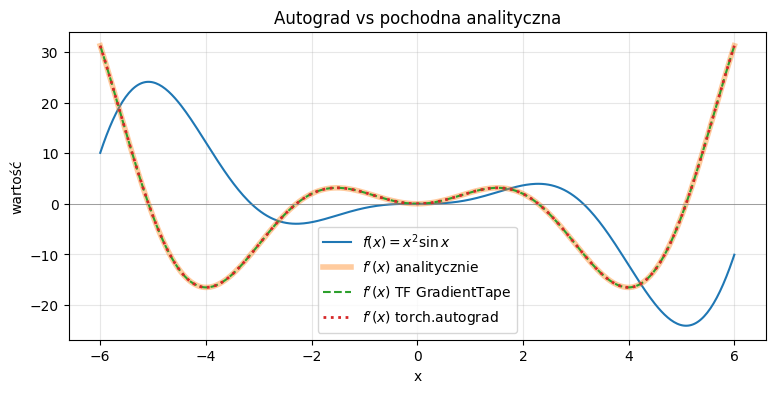

In [16]:
xs = np.linspace(-6, 6, 400).astype(np.float32)

# TF: zwykły tensor trzeba "obserwować" przez tape.watch
x_tf = tf.constant(xs)
with tf.GradientTape() as tape:
    tape.watch(x_tf)
    f_tf = x_tf ** 2 * tf.sin(x_tf)
    suma_tf = tf.reduce_sum(f_tf)     # sumowanie też musi być nagrane na taśmie!
df_tf = tape.gradient(suma_tf, x_tf).numpy()

# PyTorch
x_pt = torch.tensor(xs, requires_grad=True)
f_pt = x_pt ** 2 * torch.sin(x_pt)
f_pt.sum().backward()
df_pt = x_pt.grad.numpy()

df_analit = 2 * xs * np.sin(xs) + xs ** 2 * np.cos(xs)
print("maks. |TF - analityczna|     :", np.abs(df_tf - df_analit).max())
print("maks. |PyTorch - analityczna|:", np.abs(df_pt - df_analit).max())

plt.figure(figsize=(9, 4))
plt.plot(xs, f_pt.detach().numpy(), label="$f(x)=x^2\\sin x$")
plt.plot(xs, df_analit, lw=4, alpha=0.4, label="$f'(x)$ analitycznie")
plt.plot(xs, df_tf, "--", label="$f'(x)$ TF GradientTape")
plt.plot(xs, df_pt, ":", lw=2, label="$f'(x)$ torch.autograd")
plt.axhline(0, color="gray", lw=0.5)
plt.title("Autograd vs pochodna analityczna")
plt.xlabel("x"); plt.ylabel("wartość"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Pułapka TF:** taśma rejestruje tylko operacje wykonane **wewnątrz** bloku `with`. Gdyby `tf.reduce_sum` stało poza blokiem, `tape.gradient` zwróciłoby `None` (brak ścieżki w grafie od wyniku do `x`).

**Co obserwować:** wszystkie trzy krzywe pochodnej pokrywają się (różnice rzędu 1e-5 wynikają z precyzji `float32`). Pochodna jest równa zeru dokładnie w ekstremach $f$.

Zwróć uwagę na `f_pt.detach()` - tensora śledzącego gradient nie można bezpośrednio zamienić na NumPy; `detach()` "odcina" go od grafu.

### 2.5 Pułapki autograd w PyTorch
1. **Gradienty się akumulują (sumują)** przy kolejnych wywołaniach `backward()`. To celowe (pozwala sumować gradienty z kilku mini-batchy), ale w zwykłej pętli treningowej trzeba je zerować (`x.grad.zero_()` lub `optimizer.zero_grad()`). Zapomnienie o tym to **najczęstszy błąd** w pętli treningowej PyTorch.
2. Graf jest zwalniany po `backward()` - drugi `backward()` na tym samym grafie zgłasza błąd (chyba że `retain_graph=True`).
3. Aktualizację parametrów wykonujemy w bloku `with torch.no_grad():` - nie chcemy, żeby sam krok optymalizacji był częścią grafu.

W TF analogicznie: taśma `GradientTape` jest jednorazowa, chyba że `persistent=True`.

In [17]:
# Akumulacja gradientów w PyTorch
x = torch.tensor(3.0, requires_grad=True)
for i in range(3):
    y = x ** 2                 # dy/dx = 2x = 6
    y.backward()
    print(f"wywołanie {i + 1}: x.grad = {x.grad.item()}")   # 6, 12, 18 - suma!
x.grad.zero_()
print("po zero_():", x.grad.item())

# Wiele zmiennych i druga pochodna w TF (zagnieżdżone taśmy)
x = tf.Variable(1.5)
with tf.GradientTape() as t2:
    with tf.GradientTape() as t1:
        y = tf.sin(x) * x
    dy = t1.gradient(y, x)          # pierwsza pochodna
d2y = t2.gradient(dy, x)            # druga pochodna
print("f'(1.5) =", dy.numpy(), " f''(1.5) =", d2y.numpy())
print("analitycznie:", np.cos(1.5) * 1.5 + np.sin(1.5), 2 * np.cos(1.5) - 1.5 * np.sin(1.5))

wywołanie 1: x.grad = 6.0
wywołanie 2: x.grad = 12.0
wywołanie 3: x.grad = 18.0
po zero_(): 0.0
f'(1.5) = 1.1036007  f''(1.5) = -1.354768
analitycznie: 1.1036007891056088 -1.3547680765706758


### Zadanie 2.1 - Gradient funkcji dwóch zmiennych w TF i PyTorch
Dana jest funkcja
$$f(x, y) = \sin(x)\, y^2 + e^{x y}.$$
1. Wyprowadź na kartce pochodne cząstkowe $\partial f/\partial x$ i $\partial f/\partial y$ i wpisz je jako funkcje `df_dx_analit`, `df_dy_analit`.
2. Policz gradient w punkcie $(x, y) = (0.5, -1.0)$ za pomocą **`tf.GradientTape`** (zapisz w `grad_tf` jako listę/tablicę `[df/dx, df/dy]`).
3. To samo w **PyTorch** (`requires_grad=True`, `backward()`), wynik w `grad_pt`.

**Kryteria sukcesu:** trzy wyniki zgodne do ok. 1e-6.

**Wskazówka:** `tape.gradient(f, [x, y])` zwraca listę gradientów dla listy zmiennych.

In [18]:
x0, y0 = 0.5, -1.0

# pochodne analityczne
def df_dx_analit(x, y):
    return np.cos(x) * y ** 2 + y * np.exp(x * y)

def df_dy_analit(x, y):
    return 2 * np.sin(x) * y + x * np.exp(x * y)

# gradient w TF
x_tf = tf.Variable(x0, dtype=tf.float32)
y_tf = tf.Variable(y0, dtype=tf.float32)
with tf.GradientTape() as tape:
    f_tf = tf.sin(x_tf) * y_tf ** 2 + tf.exp(x_tf * y_tf)
grad_tf = [g.numpy() for g in tape.gradient(f_tf, [x_tf, y_tf])]

# gradient w PyTorch
x_pt = torch.tensor(x0, dtype=torch.float32, requires_grad=True)
y_pt = torch.tensor(y0, dtype=torch.float32, requires_grad=True)
f_pt = torch.sin(x_pt) * y_pt ** 2 + torch.exp(x_pt * y_pt)
f_pt.backward()
grad_pt = [x_pt.grad.item(), y_pt.grad.item()]

if grad_tf is not None and grad_pt is not None and df_dx_analit is not None:
    print("analitycznie:", df_dx_analit(x0, y0), df_dy_analit(x0, y0))
    print("TF          :", grad_tf)
    print("PyTorch     :", grad_pt)

analitycznie: 0.27105190217773933 -0.6555857473520893
TF          : [np.float32(0.27105188), np.float32(-0.65558577)]
PyTorch     : [0.27105188369750977, -0.655585765838623]


### Zadanie 2.2 - Sprawdzanie gradientu różnicami skończonymi (gradient check)
Zanim istniał autograd, każdą ręcznie wyprowadzoną pochodną sprawdzano **numerycznie**. Ta technika (*gradient checking*) przyda się nam na L2 do weryfikacji ręcznego backpropu. Pochodną cząstkową przybliżamy **różnicą centralną**:
$$\frac{\partial f}{\partial w_i} \approx \frac{f(\mathbf w + h\mathbf e_i) - f(\mathbf w - h\mathbf e_i)}{2h},$$
gdzie $\mathbf e_i$ to wektor z jedynką na pozycji $i$. Błąd przybliżenia jest rzędu $O(h^2)$ (różnica jednostronna: tylko $O(h)$).

1. Zaimplementuj `grad_numeryczny(f, w, h)` dla $f:\mathbb R^n \to \mathbb R$ (pętla po współrzędnych jest tu w porządku).
2. Komórka niżej porówna wynik z autogradem PyTorch dla funkcji $f(\mathbf w) = \log\sum_k e^{(A\mathbf w)_k} + \tfrac12\|\mathbf w\|^2$ i narysuje błąd względny w funkcji $h$.

**Kryteria sukcesu:** błąd względny $\frac{\|g_{num} - g_{auto}\|}{\|g_{num}\| + \|g_{auto}\|}$ dla $h=10^{-5}$ jest mniejszy niż $10^{-7}$; wykres błędu od $h$ ma kształt litery "V" (log-log). Zastanów się, dlaczego błąd rośnie zarówno dla dużych, jak i dla bardzo małych $h$.

**Wskazówka:** używaj `float64` - w `float32` gradient check jest bezużyteczny (za mała precyzja).

In [19]:
def grad_numeryczny(f, w, h=1e-5):
    w = np.asarray(w, dtype=np.float64)
    g = np.zeros_like(w, dtype=np.float64)
    # różnica centralna dla każdej współrzędnej w
    for i in range(w.size):
        wp = w.copy(); wp[i] += h
        wm = w.copy(); wm[i] -= h
        g[i] = (f(wp) - f(wm)) / (2 * h)
    return g

autograd : [-3.226934 -2.06264  -0.560624  0.037266]
numeryczny: [-3.226934 -2.06264  -0.560624  0.037266]
błąd względny (h=1e-5): 1.466103031535036e-11


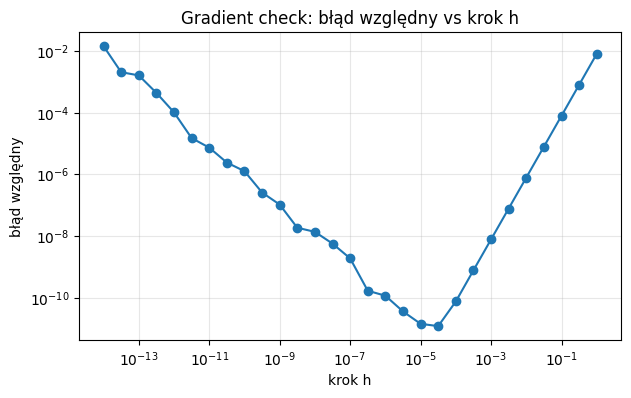

In [20]:
rng = np.random.default_rng(1)
A_mat = rng.normal(size=(6, 4))
w0 = rng.normal(size=4)

def f_np(w):                                   # wersja NumPy (do różnic skończonych)
    z = A_mat @ w
    return np.log(np.sum(np.exp(z))) + 0.5 * np.sum(w ** 2)

# Gradient z autograd (PyTorch, float64)
w_t = torch.tensor(w0, dtype=torch.float64, requires_grad=True)
f_t = torch.logsumexp(torch.tensor(A_mat) @ w_t, dim=0) + 0.5 * (w_t ** 2).sum()
f_t.backward()
g_auto = w_t.grad.numpy()

def blad_wzgledny(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-300)

g_num = grad_numeryczny(f_np, w0, h=1e-5)
print("autograd :", np.round(g_auto, 6))
print("numeryczny:", np.round(g_num, 6))
print("błąd względny (h=1e-5):", blad_wzgledny(g_num, g_auto))

# Błąd w funkcji kroku h
hs = np.logspace(-14, 0, 29)
bledy = [blad_wzgledny(grad_numeryczny(f_np, w0, h), g_auto) for h in hs]
plt.figure(figsize=(7, 4))
plt.loglog(hs, np.maximum(bledy, 1e-17), "o-")
plt.title("Gradient check: błąd względny vs krok h")
plt.xlabel("krok h"); plt.ylabel("błąd względny"); plt.grid(alpha=0.3, which="both"); plt.show()

## 3. Regresja liniowa od zera

Regresja liniowa to "najmniejsza sieć neuronowa": jedna warstwa gęsta z jednym neuronem i bez funkcji aktywacji. Rozbierzemy ją na cztery elementy z W1:

| Element | Regresja liniowa |
|---|---|
| **Dane** | $\{(\mathbf x_i, y_i)\}_{i=1}^n$, $\mathbf x_i \in \mathbb R^d$ |
| **Model** (funkcja z parametrami) | $\hat y_i = \mathbf w^\top \mathbf x_i + b$, czyli wektorowo $\hat{\mathbf y} = X\mathbf w + b$ |
| **Funkcja straty** | błąd średniokwadratowy $L(\mathbf w, b) = \frac1n\sum_i (\hat y_i - y_i)^2$ |
| **Optymalizator** | spadek gradientu (gradient descent, GD) |

**Gradienty MSE** (warto wyprowadzić samodzielnie z reguły łańcuchowej - pochodna kwadratu to $2(\hat y_i - y_i)$, a $\partial \hat y_i/\partial \mathbf w = \mathbf x_i$):
$$\frac{\partial L}{\partial \mathbf w} = \frac{2}{n} X^\top(\hat{\mathbf y} - \mathbf y), \qquad \frac{\partial L}{\partial b} = \frac{2}{n}\sum_{i=1}^n(\hat y_i - y_i).$$

**Spadek gradientu** - krok w kierunku przeciwnym do gradientu, o długości regulowanej przez **learning rate** $\eta$:
$$\mathbf w \leftarrow \mathbf w - \eta \frac{\partial L}{\partial \mathbf w}, \qquad b \leftarrow b - \eta\frac{\partial L}{\partial b}.$$

Jedno przejście przez wszystkie dane to **epoka**. Parametry ($\mathbf w, b$) model uczy się sam; **hiperparametry** ($\eta$, liczba epok, rozmiar batcha, stopień wielomianu w sekcji 6) wybieramy my - to kluczowe rozróżnienie z W1.

Dla regresji liniowej istnieje też rozwiązanie analityczne (równania normalne, $\mathbf w^* = (X^\top X)^{-1}X^\top \mathbf y$) - wykorzystamy je do sprawdzenia, czy nasz GD dochodzi do optimum. W sieciach głębokich rozwiązania analitycznego nie ma - zostaje tylko optymalizacja iteracyjna.

### 3.1 Rozgrzewka: jedna cecha, dane syntetyczne

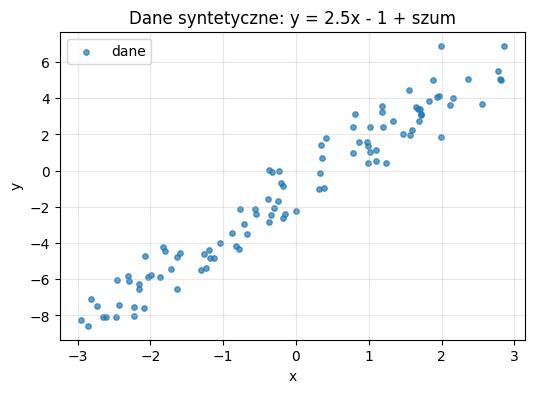

In [21]:
rng = np.random.default_rng(SEED)
n1 = 100
x1 = rng.uniform(-3, 3, size=n1)
y1 = 2.5 * x1 - 1.0 + rng.normal(scale=1.0, size=n1)    # prawdziwe w = 2.5, b = -1

plt.figure(figsize=(6, 4))
plt.scatter(x1, y1, s=15, alpha=0.7, label="dane")
plt.title("Dane syntetyczne: y = 2.5x - 1 + szum")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(alpha=0.3); plt.show()

GD     : w = 2.5128, b = -1.0130, MSE = 0.9589
polyfit: w = 2.5128, b = -1.0130


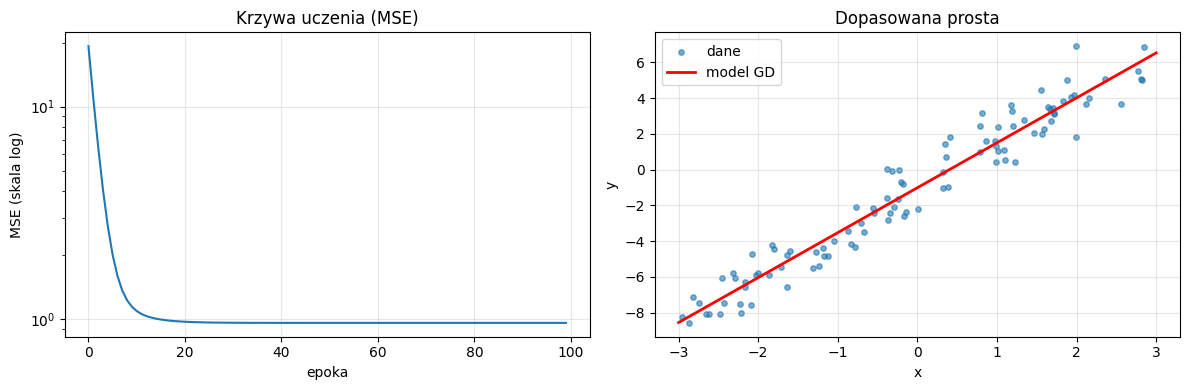

In [22]:
# Spadek gradientu dla jednej cechy - kompletny przykład
w, b = 0.0, 0.0            # inicjalizacja parametrów
lr = 0.05                  # learning rate (hiperparametr)
epoki_1d = 100             # liczba epok (hiperparametr)
historia_1d, sciezka = [], [(w, b)]

for ep in range(epoki_1d):
    y_hat = w * x1 + b                     # 1) przejście w przód (predykcja)
    err = y_hat - y1                       # 2) błędy
    loss = np.mean(err ** 2)               # 3) strata MSE
    dw = 2 * np.mean(err * x1)             # 4) gradient po w
    db = 2 * np.mean(err)                  #    gradient po b
    w -= lr * dw                           # 5) krok spadku gradientu
    b -= lr * db
    historia_1d.append(loss); sciezka.append((w, b))

w_ref, b_ref = np.polyfit(x1, y1, 1)       # rozwiązanie najmniejszych kwadratów (wzorzec)
print(f"GD     : w = {w:.4f}, b = {b:.4f}, MSE = {historia_1d[-1]:.4f}")
print(f"polyfit: w = {w_ref:.4f}, b = {b_ref:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(historia_1d); ax[0].set_yscale("log")
ax[0].set_title("Krzywa uczenia (MSE)"); ax[0].set_xlabel("epoka"); ax[0].set_ylabel("MSE (skala log)"); ax[0].grid(alpha=0.3)
xx = np.linspace(-3, 3, 50)
ax[1].scatter(x1, y1, s=15, alpha=0.6, label="dane")
ax[1].plot(xx, w * xx + b, "r", lw=2, label="model GD")
ax[1].set_title("Dopasowana prosta"); ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 3.2 Powierzchnia straty i trajektoria spadku gradientu
Dla dwóch parametrów możemy narysować $L(w, b)$ jako mapę poziomic. Spadek gradientu porusza się **prostopadle do poziomic** (gradient jest prostopadły do poziomicy). Dla MSE i modelu liniowego powierzchnia jest **wypukłą miską** - istnieje jedno minimum globalne. Dla sieci głębokich powierzchnia jest niewypukła (wiele minimów, siodła, płaskowyże) - ale lokalny mechanizm kroku jest ten sam.

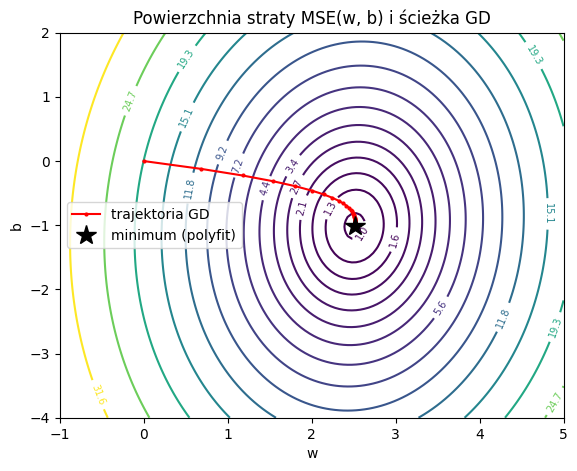

In [23]:
W_grid, B_grid = np.meshgrid(np.linspace(-1, 5, 120), np.linspace(-4, 2, 120))
# MSE dla każdego punktu siatki (broadcasting: siatka x dane)
L_grid = np.mean((W_grid[..., None] * x1 + B_grid[..., None] - y1) ** 2, axis=-1)

sc = np.array(sciezka)
plt.figure(figsize=(6.5, 5))
cs = plt.contour(W_grid, B_grid, L_grid, levels=np.logspace(0, 1.5, 15), cmap="viridis")
plt.clabel(cs, fontsize=7, fmt="%.1f")
plt.plot(sc[:, 0], sc[:, 1], "r.-", ms=4, label="trajektoria GD")
plt.plot(w_ref, b_ref, "k*", ms=15, label="minimum (polyfit)")
plt.title("Powierzchnia straty MSE(w, b) i ścieżka GD")
plt.xlabel("w"); plt.ylabel("b"); plt.legend(); plt.show()

**Co obserwować:** trajektoria najpierw szybko "spada" w kierunku dna doliny, potem zwalnia (gradient maleje przy minimum, więc kroki są coraz krótsze, mimo stałego $\eta$).

### 3.3 Prawdziwe dane: California Housing
Teraz regresja z wieloma cechami na zbiorze **California Housing** (sklearn): 20 640 okręgów spisowych w Kalifornii, 8 cech (mediana dochodu, wiek budynków, średnia liczba pokoi, ...), cel - mediana wartości domu (w setkach tysięcy USD).

Dwa ważne kroki przygotowania (szczegóły na L3 i L5):
1. **Podział train/test** - model oceniamy na danych, których nie widział.
2. **Standaryzacja cech** - cechy mają bardzo różne skale (populacja w tysiącach, szerokość geograficzna ~35). Bez standaryzacji powierzchnia straty jest bardzo "wydłużona" i GD wymaga mikroskopijnego learning rate. Średnią i odchylenie liczymy **wyłącznie na zbiorze treningowym** i stosujemy je do testowego - inaczej informacja ze zbioru testowego "przecieka" do treningu (data leakage, W4).

In [24]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

dom = fetch_california_housing()
X_all, y_all = dom.data.astype(np.float64), dom.target.astype(np.float64)
if SZYBKI_TRYB:                       # tryb szybki: tylko 2000 pierwszych próbek
    X_all, y_all = X_all[:2000], y_all[:2000]
print("cechy:", list(dom.feature_names))
print("X:", X_all.shape, " y:", y_all.shape)

X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=SEED)

# Standaryzacja - statystyki TYLKO ze zbioru treningowego
mu, sigma = X_tr.mean(axis=0), X_tr.std(axis=0)
X_tr_s = (X_tr - mu) / sigma
X_te_s = (X_te - mu) / sigma
n_tr, d = X_tr_s.shape
print("train:", X_tr_s.shape, " test:", X_te_s.shape)
print("średnie cech po standaryzacji (train):", np.round(X_tr_s.mean(axis=0), 3))

cechy: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
X: (2000, 8)  y: (2000,)
train: (1600, 8)  test: (400, 8)
średnie cech po standaryzacji (train): [ 0.  0. -0. -0. -0. -0.  0. -0.]


**Baseline.** Zanim zaczniemy trenować, warto wiedzieć, jaki wynik daje "model" najprostszy z możliwych - przewidywanie stałej (średniej z treningu). Każdy model, który nie jest lepszy od baseline, jest bezwartościowy. Do tego referencja: rozwiązanie analityczne najmniejszych kwadratów (`np.linalg.lstsq`), które jest dokładnym minimum MSE na zbiorze treningowym.

In [25]:
def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

# Baseline: stała = średnia z treningu
print("Baseline (średnia) MSE test:", round(mse(y_te, np.full_like(y_te, y_tr.mean())), 4))

# Rozwiązanie analityczne (najmniejsze kwadraty) - dokładne minimum na train
Xb_tr = np.hstack([X_tr_s, np.ones((n_tr, 1))])          # kolumna jedynek = bias
theta_ls = np.linalg.lstsq(Xb_tr, y_tr, rcond=None)[0]
w_ls, b_ls = theta_ls[:-1], theta_ls[-1]
loss_opt = mse(y_tr, X_tr_s @ w_ls + b_ls)
print("Najmniejsze kwadraty: MSE train =", round(loss_opt, 4),
      " MSE test =", round(mse(y_te, X_te_s @ w_ls + b_ls), 4))

Baseline (średnia) MSE test: 0.9137
Najmniejsze kwadraty: MSE train = 0.2818  MSE test = 0.241


### Zadanie 3.1 - Wektorowy spadek gradientu w NumPy (wiele cech)
Uzupełnij funkcję `gd_linreg(X, y, lr, epoki)`, która trenuje regresję liniową spadkiem gradientu (full-batch) i zwraca `w`, `b` oraz listę wartości MSE z każdej epoki (`historia`). Wykorzystaj wzory z początku sekcji 3. **Bez pętli po próbkach** - tylko operacje macierzowe.

W każdej epoce: predykcja $\hat{\mathbf y} = X\mathbf w + b$ -> błąd $\hat{\mathbf y} - \mathbf y$ -> zapisz MSE do historii -> gradienty -> aktualizacja.

**Kryteria sukcesu (pełny tryb):** po 500 epokach z `lr = 0.2` MSE na treningu różni się od rozwiązania analitycznego `loss_opt` o mniej niż 1%, a wagi są bliskie `w_ls`; MSE testowe ok. 0.55 (znacznie lepiej niż baseline ~1.3).

**Wskazówka:** sprawdź kształty: `X` `(n, d)`, `w` `(d,)`, `y` `(n,)`, gradient po `w` `(d,)`.

In [26]:
EPOKI_GD = 50 if SZYBKI_TRYB else 500

def gd_linreg(X, y, lr=0.2, epoki=EPOKI_GD):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia = []
    for ep in range(epoki):
        # predykcja
        y_hat = X @ w + b
        # błąd
        err = y_hat - y
        # MSE do historii
        historia.append(np.mean(err ** 2))
        # gradienty
        dw = 2 * X.T @ err / n
        db = 2 * np.mean(err)
        # aktualizacja w i b
        w -= lr * dw
        b -= lr * db
    return w, b, historia

czas: 0.03 s
MSE train GD = 0.2829  vs  optimum = 0.2818  (różnica 0.37%)
MSE test GD  = 0.2371
max |w_gd - w_ls| = 0.1456


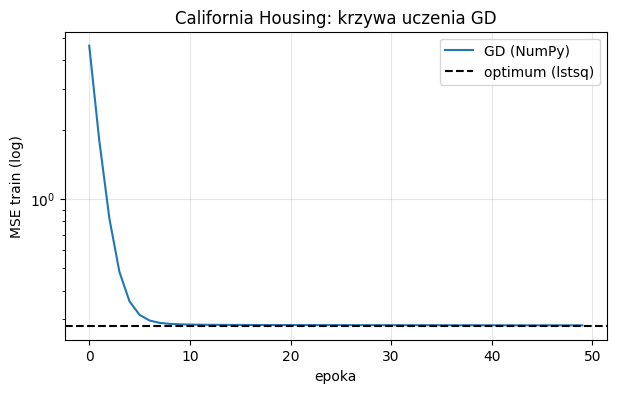

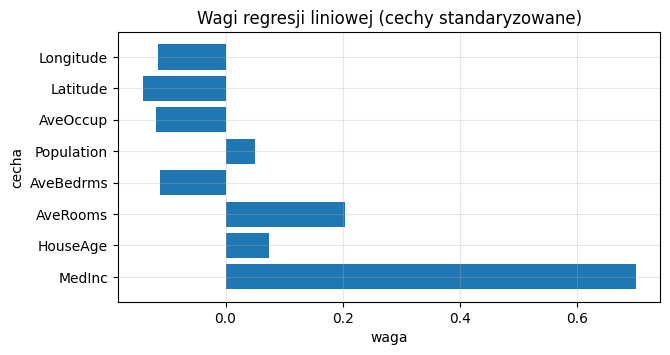

In [27]:
t0 = time.perf_counter()
w_gd, b_gd, hist_gd = gd_linreg(X_tr_s, y_tr, lr=0.2, epoki=EPOKI_GD)
print(f"czas: {time.perf_counter() - t0:.2f} s")
if len(hist_gd) > 0:
    print(f"MSE train GD = {hist_gd[-1]:.4f}  vs  optimum = {loss_opt:.4f}  (różnica {100 * (hist_gd[-1] / loss_opt - 1):.2f}%)")
    print("MSE test GD  =", round(mse(y_te, X_te_s @ w_gd + b_gd), 4))
    print("max |w_gd - w_ls| =", np.abs(w_gd - w_ls).max().round(4))

    plt.figure(figsize=(7, 4))
    plt.plot(hist_gd, label="GD (NumPy)")
    plt.axhline(loss_opt, color="k", ls="--", label="optimum (lstsq)")
    plt.yscale("log"); plt.title("California Housing: krzywa uczenia GD")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

    # Które cechy mają największy wpływ? (cechy są standaryzowane, więc wagi są porównywalne)
    plt.figure(figsize=(7, 3.5))
    plt.barh(dom.feature_names, w_gd)
    plt.title("Wagi regresji liniowej (cechy standaryzowane)"); plt.xlabel("waga"); plt.ylabel("cecha")
    plt.grid(alpha=0.3); plt.show()

### 3.4 Ta sama regresja w PyTorch - najpierw "ręcznie" z autograd
Teraz nie liczymy gradientów ręcznie: wystarczy zdefiniować stratę, a `loss.backward()` wypełni `w.grad` i `b.grad`. Zwróć uwagę na trzy elementy, które będą w **każdej** pętli treningowej PyTorch:
1. obliczenie straty (forward),
2. `loss.backward()` (gradienty),
3. aktualizacja parametrów w `torch.no_grad()` i **wyzerowanie gradientów**.

Dane przenosimy raz na `DEVICE` (GPU), konwertując na `float32`.

In [28]:
Xtr_t = torch.tensor(X_tr_s, dtype=torch.float32, device=DEVICE)
ytr_t = torch.tensor(y_tr, dtype=torch.float32, device=DEVICE)
Xte_t = torch.tensor(X_te_s, dtype=torch.float32, device=DEVICE)
yte_t = torch.tensor(y_te, dtype=torch.float32, device=DEVICE)

w_t = torch.zeros(d, device=DEVICE, requires_grad=True)   # parametry śledzone przez autograd
b_t = torch.zeros(1, device=DEVICE, requires_grad=True)
lr = 0.2
hist_pt = []
for ep in range(EPOKI_GD):
    y_hat = Xtr_t @ w_t + b_t                 # forward
    loss = ((y_hat - ytr_t) ** 2).mean()      # MSE
    loss.backward()                            # autograd liczy w_t.grad, b_t.grad
    with torch.no_grad():                      # krok optymalizacji poza grafem
        w_t -= lr * w_t.grad
        b_t -= lr * b_t.grad
        w_t.grad.zero_(); b_t.grad.zero_()     # zerowanie gradientów!
    hist_pt.append(loss.item())

print(f"PyTorch (autograd): MSE train = {hist_pt[-1]:.4f}")
print("max |w_torch - w_ls| =", np.abs(w_t.detach().cpu().numpy() - w_ls).max().round(4))

PyTorch (autograd): MSE train = 0.2829
max |w_torch - w_ls| = 0.1456


### 3.5 ...i w "standardowym" stylu PyTorch: `nn.Linear` + optymalizator
W praktyce nie tworzymy parametrów ręcznie: warstwa `nn.Linear(d, 1)` zawiera wagi i bias, funkcja straty `nn.MSELoss()`, a optymalizator `torch.optim.SGD` wykonuje krok aktualizacji (`step()`) i zeruje gradienty (`zero_grad()`). To dokładnie ten sam algorytm co wyżej - tylko krócej zapisany. Ten wzorzec zobaczysz na L2 i L5.

Uwaga na kształt: `nn.Linear` zwraca `(n, 1)`, a `y` ma `(n,)` - dlatego `squeeze(1)` (pamiętasz broadcasting z sekcji 1.4?).

In [29]:
torch.manual_seed(SEED)
model_lin = torch.nn.Linear(d, 1).to(DEVICE)      # w (1 x d) i b - inicjalizowane losowo
opt = torch.optim.SGD(model_lin.parameters(), lr=0.2)
loss_fn = torch.nn.MSELoss()

for ep in range(EPOKI_GD):
    opt.zero_grad()                                # 1) zerowanie gradientów
    y_hat = model_lin(Xtr_t).squeeze(1)            # 2) forward, (n,1) -> (n,)
    loss = loss_fn(y_hat, ytr_t)                   # 3) strata
    loss.backward()                                # 4) gradienty
    opt.step()                                     # 5) krok optymalizatora

with torch.no_grad():
    mse_te_lin = loss_fn(model_lin(Xte_t).squeeze(1), yte_t).item()
print(f"nn.Linear + SGD: MSE train = {loss.item():.4f}, MSE test = {mse_te_lin:.4f}")

nn.Linear + SGD: MSE train = 0.2859, MSE test = 0.2344


### Zadanie 3.2 - Regresja liniowa w TensorFlow z `GradientTape`
Napisz ten sam trening w TensorFlow:
1. Parametry jako `tf.Variable`: `w_tf` o kształcie `(d,)` (zera) i `b_tf` (skalar 0.0), `float32`.
2. W pętli po `EPOKI_GD` epokach: w `tf.GradientTape` policz predykcję (`tf.linalg.matvec(X, w) + b`) i MSE, pobierz gradienty `tape.gradient(loss, [w_tf, b_tf])` i zaktualizuj parametry metodą `assign_sub`.
3. Zapisuj stratę do listy `hist_tf` (`float(loss)`).

**Kryteria sukcesu:** końcowe MSE train zgodne z wersją NumPy i PyTorch (różnice < 1e-3), wykres trzech krzywych uczenia pokrywa się.

**Wskazówka:** dane zamień raz na `tf.constant(..., dtype=tf.float32)`. Zamiast ręcznego `assign_sub` możesz też użyć `keras.optimizers.SGD(learning_rate=0.2).apply_gradients(zip(grads, vars))`.

MSE train: NumPy 0.28288 | PyTorch 0.28288 | TF 0.28288


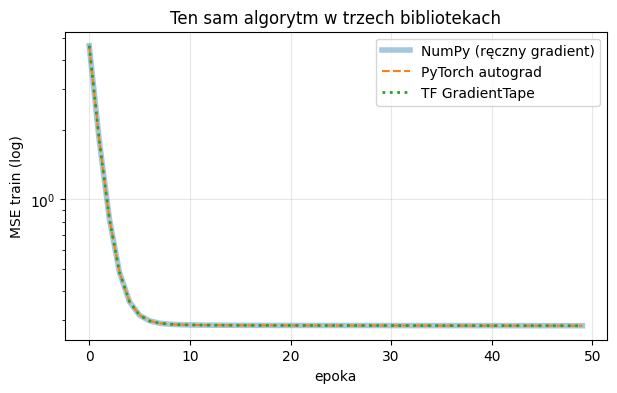

In [30]:
Xtr_tf = tf.constant(X_tr_s, dtype=tf.float32)
ytr_tf = tf.constant(y_tr, dtype=tf.float32)

# zmienne w_tf, b_tf
w_tf = tf.Variable(tf.zeros(d, dtype=tf.float32))
b_tf = tf.Variable(tf.zeros((), dtype=tf.float32))
# lista hist_tf
hist_tf = []
# pętla z GradientTape
for ep in range(EPOKI_GD):
    with tf.GradientTape() as tape:
        y_hat = tf.linalg.matvec(Xtr_tf, w_tf) + b_tf
        loss = tf.reduce_mean((y_hat - ytr_tf) ** 2)
    grads = tape.gradient(loss, [w_tf, b_tf])
    w_tf.assign_sub(0.2 * grads[0])
    b_tf.assign_sub(0.2 * grads[1])
    hist_tf.append(float(loss))

if len(hist_tf) > 0:
    print(f"MSE train: NumPy {hist_gd[-1]:.5f} | PyTorch {hist_pt[-1]:.5f} | TF {hist_tf[-1]:.5f}")
    plt.figure(figsize=(7, 4))
    plt.plot(hist_gd, lw=4, alpha=0.4, label="NumPy (ręczny gradient)")
    plt.plot(hist_pt, "--", label="PyTorch autograd")
    plt.plot(hist_tf, ":", lw=2, label="TF GradientTape")
    plt.yscale("log"); plt.title("Ten sam algorytm w trzech bibliotekach")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Hiperparametr learning rate i liczba epok

Learning rate $\eta$ to najważniejszy hiperparametr optymalizacji (W1, W3):
- **za mały** - zbieżność bardzo wolna; po zadanej liczbie epok model jest wciąż niedouczony (underfitting "optymalizacyjny"),
- **dobry** - szybki spadek straty do minimum,
- **za duży** - kroki "przeskakują" dolinę, strata oscyluje, a powyżej pewnego progu **rośnie wykładniczo (rozbieżność)** - w praktyce pojawia się `nan` lub `inf`.

### Skąd się bierze próg rozbieżności?
Dla straty kwadratowej (a MSE regresji liniowej jest kwadratowa względem $\boldsymbol\theta = (\mathbf w, b)$) gradient jest liniowy: $\nabla L(\boldsymbol\theta) = H(\boldsymbol\theta - \boldsymbol\theta^*)$, gdzie **hesjan** $H = \frac{2}{n}\tilde X^\top \tilde X$ ($\tilde X$ - dane z dołączoną kolumną jedynek). Krok GD daje
$$\boldsymbol\theta_{t+1} - \boldsymbol\theta^* = (I - \eta H)(\boldsymbol\theta_t - \boldsymbol\theta^*).$$
W kierunku wektora własnego $H$ o wartości własnej $\lambda$ błąd mnoży się co krok przez $(1 - \eta\lambda)$. Zbieżność wymaga $|1 - \eta\lambda| < 1$ dla wszystkich $\lambda$, czyli
$$\eta < \eta_{kryt} = \frac{2}{\lambda_{max}}.$$
Z kolei tempo zbieżności w "najwolniejszym" kierunku zależy od $\eta\lambda_{min}$ - stosunek $\lambda_{max}/\lambda_{min}$ (**uwarunkowanie**) mówi, jak trudny jest problem. Standaryzacja cech poprawia uwarunkowanie - dlatego tak bardzo pomaga.

W sieciach głębokich strata nie jest kwadratowa, ale lokalnie zachowuje się podobnie - stąd ta sama jakościowa intuicja.

### Zadanie 4.1 - Eksperyment: za mały, dobry i za duży learning rate
**Hipoteza (UGŁ_U01):** "GD jest zbieżny dla $\eta < 2/\lambda_{max}$ i rozbieżny powyżej tej wartości; mniejszy $\eta$ wymaga proporcjonalnie więcej epok."

1. Zbuduj `Xb = [X_tr_s, 1]` (kolumna jedynek), policz hesjan `H` $= \frac2n \tilde X^\top\tilde X$, jego wartości własne (`np.linalg.eigvalsh`), `lam_max`, `lam_min`, uwarunkowanie i `lr_kryt = 2 / lam_max`.
2. Wytrenuj model funkcją `gd_linreg` (z Zadania 3.1) dla learning rate z listy `lrs` (gotowa poniżej, zawiera wartości tuż poniżej i tuż powyżej `lr_kryt`). Zapisz historie w słowniku `historie[lr] = hist`.
3. Komórka niżej narysuje krzywe i policzy, po ilu epokach strata zbliża się do optimum na 1%.

**Kryteria sukcesu:** dla `0.98 * lr_kryt` strata maleje (oscylując), dla `1.05 * lr_kryt` rośnie - hipoteza potwierdzona; potrafisz wskazać lr "za mały" (niedouczony po wszystkich epokach).

**Wskazówka:** `np.linalg.eigvalsh` jest przeznaczone dla macierzy symetrycznych (a hesjan jest symetryczny).

In [31]:
# Xb = [X_tr_s, 1] (kolumna jedynek)
Xb = np.hstack([X_tr_s, np.ones((n_tr, 1))])
# hesjan
H = (2.0 / n_tr) * Xb.T @ Xb
# wartości własne
eigs = np.linalg.eigvalsh(H)
lam_min, lam_max = eigs[0], eigs[-1]
# lr_kryt
lr_kryt = 2.0 / lam_max
print(f"lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.4f}, uwarunkowanie = {lam_max / lam_min:.1f}")
print(f"teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = {lr_kryt:.4f}")

EPOKI_LR = 40 if SZYBKI_TRYB else 200
lrs = [0.001, 0.01, 0.1, round(0.5 * lr_kryt, 4), round(0.98 * lr_kryt, 4), round(1.05 * lr_kryt, 4)]
historie = {}
for lr_ in lrs:
    # trening gd_linreg dla każdego lr, zapis historii
    _, _, h = gd_linreg(X_tr_s, y_tr, lr=lr_, epoki=EPOKI_LR)
    historie[lr_] = h

lambda_min = 0.0480, lambda_max = 4.3339, uwarunkowanie = 90.3
teoretyczny próg rozbieżności lr_kryt = 2/lambda_max = 0.4615


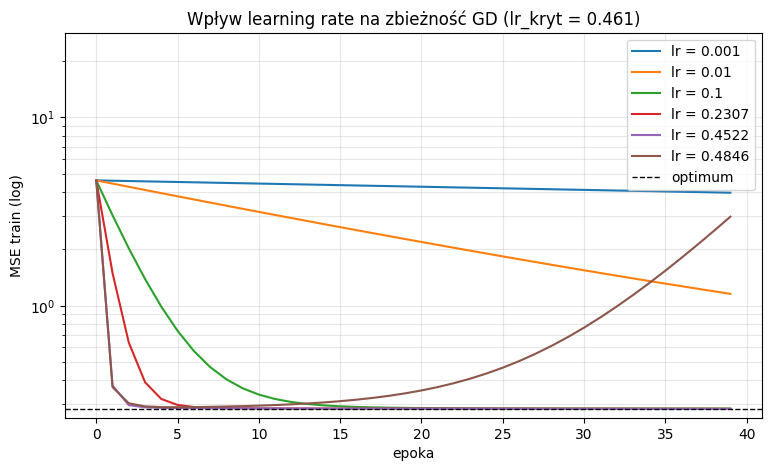

lr        | MSE po ostatniej epoce | epoki do 1% od optimum
0.001     |                   3.98 | nie osiągnięto
0.01      |                  1.155 | nie osiągnięto
0.1       |                 0.2837 | 24
0.2307    |                  0.283 | 10
0.4522    |                 0.2824 | 8
0.4846    |                  2.967 | nie osiągnięto


In [32]:
if historie:
    plt.figure(figsize=(9, 5))
    for lr_, h in historie.items():
        plt.plot(h, label=f"lr = {lr_}")
    plt.axhline(loss_opt, color="k", ls="--", lw=1, label="optimum")
    plt.yscale("log"); plt.ylim(loss_opt * 0.9, max(10, loss_opt * 100))
    plt.title(f"Wpływ learning rate na zbieżność GD (lr_kryt = {lr_kryt:.3f})")
    plt.xlabel("epoka"); plt.ylabel("MSE train (log)"); plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

    print("lr        | MSE po ostatniej epoce | epoki do 1% od optimum")
    for lr_, h in historie.items():
        h = np.array(h)
        ok = np.where(h <= 1.01 * loss_opt)[0]
        print(f"{lr_:<9} | {h[-1]:>22.4g} | {ok[0] if len(ok) else 'nie osiągnięto'}")

**Co obserwować i jak interpretować:**
- `lr = 0.001` - strata maleje bardzo powoli; po wszystkich epokach model jest daleko od optimum. Więcej epok "naprawiłoby" problem - liczba epok i lr są ze sobą sprzężone.
- `0.5 * lr_kryt` - zwykle najszybsza zbieżność w tym zestawie.
- `0.98 * lr_kryt` - strata maleje, ale model "skacze" z jednej strony doliny na drugą (w kierunku $\lambda_{max}$ czynnik $1 - \eta\lambda \approx -0.96$ - zmiana znaku co krok!).
- `1.05 * lr_kryt` - rozbieżność: strata rośnie wykładniczo. W dłuższym treningu doszłoby do `inf`/`nan`.

Typowy objaw zbyt dużego learning rate w sieciach głębokich: strata `nan` po kilku krokach - pierwszy odruch to zmniejszenie lr 10x.

## 5. Mini-batch vs full-batch

Dotąd w każdym kroku liczyliśmy gradient na **całym** zbiorze treningowym (*full-batch GD*). Przy milionach próbek (obrazy, tekst) jest to niewykonalne - nie mieszczą się w pamięci GPU, a jeden krok trwałby bardzo długo. Rozwiązanie: **stochastyczny spadek gradientu na mini-batchach** (mini-batch SGD):
1. na początku epoki **losowo permutujemy** dane,
2. dzielimy je na porcje (batche) po $B$ próbek,
3. dla każdego batcha liczymy gradient tylko na nim i wykonujemy krok.

Gradient z mini-batcha jest **nieobciążonym, ale zaszumionym** estymatorem pełnego gradientu; wariancja szumu maleje jak $1/B$.

| Rozmiar batcha | Kroków na epokę | Szum gradientu | Wykorzystanie GPU |
|---|---|---|---|
| $B = 1$ (czyste SGD) | $n$ | bardzo duży | słabe (brak równoległości) |
| $B = 32-256$ (typowo) | $n/B$ | umiarkowany | dobre |
| $B = n$ (full-batch) | 1 | brak | wymaga dużo pamięci |

Mniejszy batch = więcej (tańszych, zaszumionych) kroków w epoce. Szum bywa nawet korzystny - pomaga uciekać z płaskich obszarów i działa jak lekka regularyzacja. **Rozmiar batcha i learning rate są sprzężone** - większy batch zwykle znosi większy lr.

### Zadanie 5.1 - Implementacja mini-batch SGD i porównanie rozmiarów batcha
Uzupełnij wnętrze pętli epok w funkcji `minibatch_gd`:
1. wylosuj permutację indeksów (`rng.permutation(n)`),
2. iteruj po kolejnych porcjach `perm[start:start + batch_size]`,
3. dla każdej porcji policz gradient MSE (wzory jak w 3.1, ale z $n$ zastąpionym liczbą próbek w batchu - ostatni batch może być mniejszy!) i zaktualizuj `w`, `b`.

Strata **na całym zbiorze treningowym** i czas są zapisywane po każdej epoce (kod gotowy).

**Kryteria sukcesu:** wykres "MSE vs epoka" pokazuje, że małe batche osiągają niską stratę w mniejszej liczbie epok (więcej kroków na epokę), ale ich krzywa jest bardziej "poszarpana"; wykres "MSE vs czas" pokazuje koszt dużej liczby małych kroków w Pythonie. Sformułuj wniosek w 2-3 zdaniach.

**Wskazówka:** użyj `len(idx)` zamiast `batch_size` w mianowniku gradientu.

In [33]:
def minibatch_gd(X, y, lr=0.05, epoki=20, batch_size=32, seed=0):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    historia, czasy = [], []
    t0 = time.perf_counter()
    for ep in range(epoki):
        # permutacja
        perm = rng.permutation(n)
        # pętla po mini-batchach
        for start in range(0, n, batch_size):
            idx = perm[start:start + batch_size]
            Xb, yb = X[idx], y[idx]
            # gradient na batchu (ostatni batch może być mniejszy)
            nb = len(idx)
            err = Xb @ w + b - yb
            dw = 2 * Xb.T @ err / nb
            db = 2 * np.mean(err)
            # aktualizacja
            w -= lr * dw
            b -= lr * db
        historia.append(np.mean((X @ w + b - y) ** 2))   # strata na całym zbiorze train
        czasy.append(time.perf_counter() - t0)
    return w, b, historia, czasy

    B = 16: kroków/epokę =   100, MSE końcowe = 0.3558, czas = 0.02 s
    B = 64: kroków/epokę =    25, MSE końcowe = 0.2928, czas = 0.00 s
   B = 256: kroków/epokę =     7, MSE końcowe = 0.2974, czas = 0.00 s
full-batch: kroków/epokę =     1, MSE końcowe = 2.1097, czas = 0.00 s


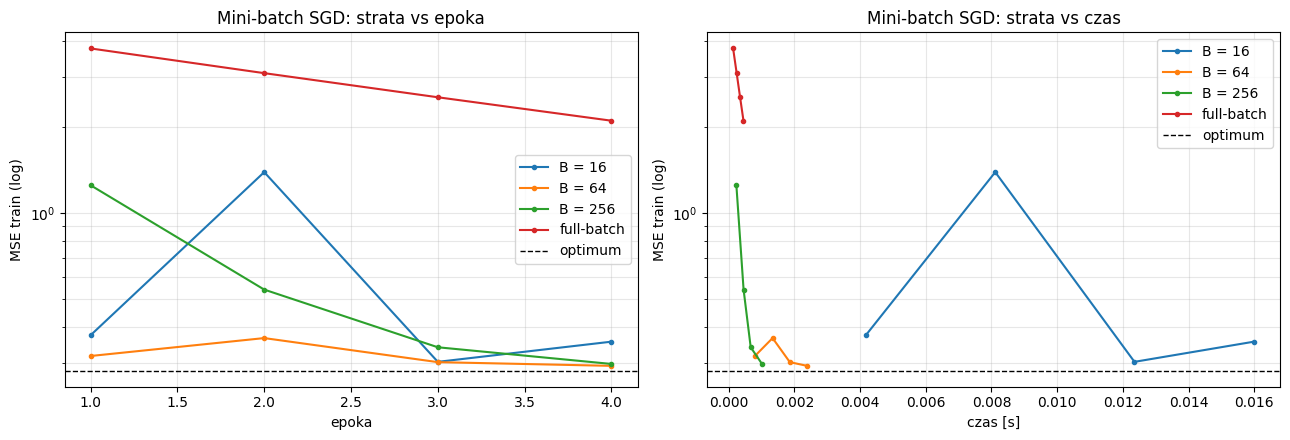

In [34]:
EPOKI_MB = 4 if SZYBKI_TRYB else 30
wyniki_mb = {}
for bs in [16, 64, 256, n_tr]:
    _, _, h, c = minibatch_gd(X_tr_s, y_tr, lr=0.05, epoki=EPOKI_MB, batch_size=bs)
    nazwa = "full-batch" if bs == n_tr else f"B = {bs}"
    wyniki_mb[nazwa] = (h, c)
    print(f"{nazwa:>10}: kroków/epokę = {math.ceil(n_tr / bs):5d}, MSE końcowe = {h[-1]:.4f}, czas = {c[-1]:.2f} s")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nazwa, (h, c) in wyniki_mb.items():
    ax[0].plot(range(1, len(h) + 1), h, "o-", ms=3, label=nazwa)
    ax[1].plot(c, h, "o-", ms=3, label=nazwa)
for a_, xl in zip(ax, ["epoka", "czas [s]"]):
    a_.axhline(loss_opt, color="k", ls="--", lw=1, label="optimum")
    a_.set_yscale("log"); a_.set_xlabel(xl); a_.set_ylabel("MSE train (log)"); a_.grid(alpha=0.3, which="both"); a_.legend()
ax[0].set_title("Mini-batch SGD: strata vs epoka"); ax[1].set_title("Mini-batch SGD: strata vs czas")
plt.tight_layout(); plt.show()

### 5.1 Mini-batche "po bibliotecznemu": `DataLoader` w PyTorch
W PyTorch tasowanie i dzielenie na batche robi `DataLoader` (opakowanie na `Dataset`). W Keras to samo zapewnia argument `batch_size` w `model.fit`. Poniżej ten sam mini-batch SGD z `nn.Linear` - zwróć uwagę, jak mało kodu potrzeba. Szczegółowo omówimy to na L2 i L5.

In [35]:
from torch.utils.data import TensorDataset, DataLoader

ds = TensorDataset(torch.tensor(X_tr_s, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32))
loader = DataLoader(ds, batch_size=64, shuffle=True)     # shuffle=True -> nowa permutacja co epokę

torch.manual_seed(SEED)
model_mb = torch.nn.Linear(d, 1).to(DEVICE)
opt = torch.optim.SGD(model_mb.parameters(), lr=0.05)
for ep in range(EPOKI_MB):
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)              # batch na GPU
        opt.zero_grad()
        loss = torch.nn.functional.mse_loss(model_mb(xb).squeeze(1), yb)
        loss.backward()
        opt.step()
with torch.no_grad():
    print("DataLoader + SGD (B = 64): MSE train =",
          round(torch.nn.functional.mse_loss(model_mb(Xtr_t).squeeze(1), ytr_t).item(), 4))

DataLoader + SGD (B = 64): MSE train = 0.4828


## 6. Regresja wielomianowa i przeuczenie (overfitting)

Model liniowy można rozszerzyć o **cechy wielomianowe**: $\phi(x) = [1, x, x^2, \dots, x^D]$, a następnie $\hat y = \mathbf w^\top \phi(x)$. Model jest nadal liniowy względem parametrów (więc wciąż działa lstsq), ale nieliniowy względem $x$. **Stopień $D$ to hiperparametr sterujący pojemnością (capacity) modelu.**

Klasyczny eksperyment (Bishop, "Pattern Recognition and Machine Learning"): dane z funkcji $\sin(2\pi x)$ z szumem, tylko **20 punktów treningowych**.
- Mały $D$ (np. 1) - model zbyt prosty: duży błąd i na treningu, i na walidacji -> **underfitting** (wysoki bias).
- Odpowiedni $D$ (ok. 3-5) - dobre dopasowanie kształtu.
- Duży $D$ (np. 15) - model "przechodzi" przez punkty treningowe (błąd train ≈ 0), ale między nimi oscyluje dziko -> **overfitting** (wysoka wariancja): model nauczył się szumu.

Dlatego **błąd na zbiorze treningowym nie mówi nic o jakości modelu** - hiperparametry dobieramy na **zbiorze walidacyjnym**, a ostateczną ocenę robimy raz, na **zbiorze testowym** (W1: podział train/val/test). Sieci głębokie mają ogromną pojemność, więc ten problem jest w DL centralny (regularyzacja - W3, L3).

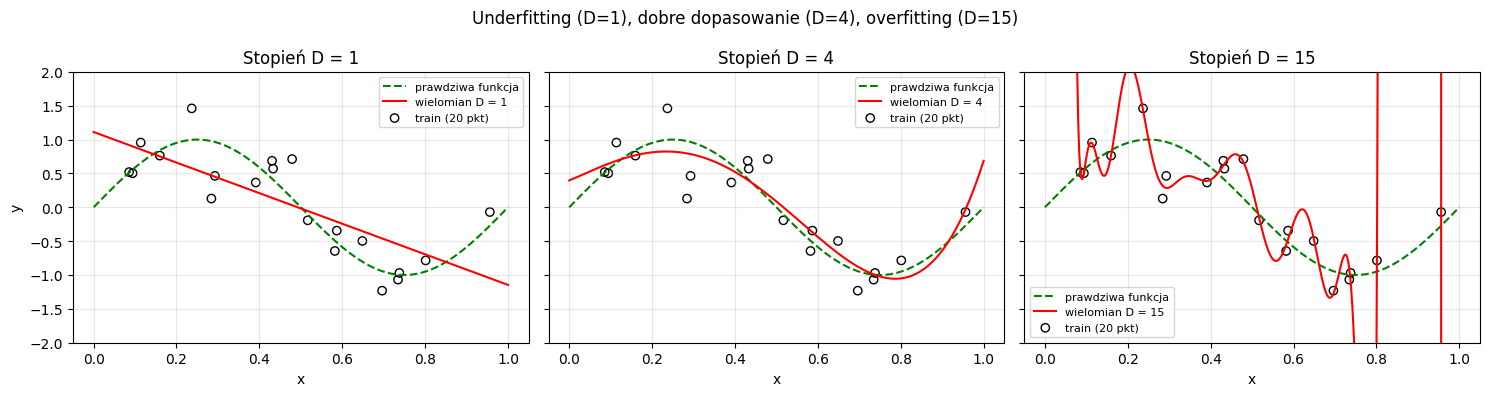

In [36]:
rng = np.random.default_rng(3)
def prawdziwa_f(x):
    return np.sin(2 * np.pi * x)

n_train_p, n_val_p = 20, 200
x_trp = rng.uniform(0, 1, n_train_p); y_trp = prawdziwa_f(x_trp) + rng.normal(scale=0.3, size=n_train_p)
x_vap = rng.uniform(0, 1, n_val_p);   y_vap = prawdziwa_f(x_vap) + rng.normal(scale=0.3, size=n_val_p)

def poly_features(x, stopien):
    # Macierz Vandermonde'a: kolumny 1, x, x^2, ..., x^stopien
    return np.vander(x, stopien + 1, increasing=True)

def dopasuj_wielomian(x, y, stopien):
    Phi = poly_features(x, stopien)
    return np.linalg.lstsq(Phi, y, rcond=None)[0]       # najmniejsze kwadraty

xx = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax_, D in zip(axes, [1, 4, 15]):
    wD = dopasuj_wielomian(x_trp, y_trp, D)
    ax_.plot(xx, prawdziwa_f(xx), "g--", label="prawdziwa funkcja")
    ax_.plot(xx, poly_features(xx, D) @ wD, "r", label=f"wielomian D = {D}")
    ax_.scatter(x_trp, y_trp, edgecolors="k", facecolors="none", label="train (20 pkt)")
    ax_.set_ylim(-2, 2); ax_.set_title(f"Stopień D = {D}"); ax_.set_xlabel("x"); ax_.grid(alpha=0.3); ax_.legend(fontsize=8)
axes[0].set_ylabel("y")
plt.suptitle("Underfitting (D=1), dobre dopasowanie (D=4), overfitting (D=15)"); plt.tight_layout(); plt.show()

### Zadanie 6.1 - Krzywa train vs walidacja w funkcji stopnia wielomianu
1. Dla stopni $D = 0, 1, \dots, 15$ dopasuj wielomian do danych treningowych (`dopasuj_wielomian`) i policz MSE na train oraz na walidacji. Zapisz w listach `mse_train_D`, `mse_val_D`.
2. Wyznacz `najlepszy_D` - stopień o najmniejszym błędzie walidacyjnym.
3. Komórka niżej narysuje obie krzywe (skala log).

**Kryteria sukcesu:** krzywa train maleje monotonicznie (prawie do zera dla D ≥ 15), krzywa walidacyjna ma kształt litery **U** z minimum przy D ≈ 3-6. Potrafisz wskazać na wykresie strefę underfittingu i overfittingu.

**Hipoteza do sprawdzenia:** "Większy model zawsze daje mniejszy błąd treningowy, ale nie walidacyjny."

najlepszy stopień wg walidacji: 3  MSE val = 0.0911


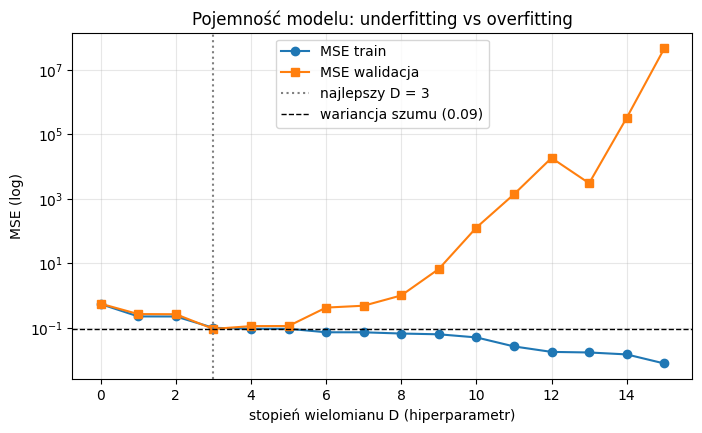

In [37]:
stopnie = list(range(16))
# pętla po stopniach
mse_train_D, mse_val_D, najlepszy_D = [], [], None
for D in stopnie:
    wD = dopasuj_wielomian(x_trp, y_trp, D)
    # MSE train i val
    mse_train_D.append(mse(y_trp, poly_features(x_trp, D) @ wD))
    mse_val_D.append(mse(y_vap, poly_features(x_vap, D) @ wD))
# najlepszy_D
najlepszy_D = int(np.argmin(mse_val_D))

if mse_val_D:
    print("najlepszy stopień wg walidacji:", najlepszy_D, " MSE val =", round(mse_val_D[najlepszy_D], 4))
    plt.figure(figsize=(8, 4.5))
    plt.plot(stopnie, mse_train_D, "o-", label="MSE train")
    plt.plot(stopnie, mse_val_D, "s-", label="MSE walidacja")
    plt.axvline(najlepszy_D, color="gray", ls=":", label=f"najlepszy D = {najlepszy_D}")
    plt.axhline(0.3 ** 2, color="k", ls="--", lw=1, label="wariancja szumu (0.09)")
    plt.yscale("log"); plt.title("Pojemność modelu: underfitting vs overfitting")
    plt.xlabel("stopień wielomianu D (hiperparametr)"); plt.ylabel("MSE (log)"); plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

### Zadanie 6.2 - Regularyzacja L2 (ridge) jako "lekarstwo" na przeuczenie
Zamiast zmniejszać stopień, możemy zostawić duży model ($D = 15$), ale **karać duże wagi**. Strata z karą L2:
$$L_\lambda(\mathbf w) = \frac1n\|\Phi\mathbf w - \mathbf y\|^2 + \lambda\|\mathbf w\|^2,$$
ma rozwiązanie analityczne $\mathbf w_\lambda = (\Phi^\top\Phi + n\lambda I)^{-1}\Phi^\top\mathbf y$. W sieciach neuronowych to samo nazywa się **weight decay** (W3, L3). $\lambda$ to kolejny hiperparametr.

1. Zaimplementuj `dopasuj_ridge(x, y, stopien, lam)` (użyj `np.linalg.solve`, nie odwracaj macierzy jawnie; biasu - pierwszej kolumny - zwyczajowo nie karzemy: wyzeruj odpowiedni element macierzy kary).
2. Dla $\lambda$ z `lambdy` (od $10^{-12}$ do $10$) policz MSE train i val przy $D = 15$; wybierz najlepszą $\lambda$ wg walidacji.
3. Komórka rysuje krzywe i dopasowanie dla najlepszej $\lambda$.

**Kryteria sukcesu:** krzywa walidacyjna względem $\lambda$ ma minimum (zbyt mała kara - overfitting, zbyt duża - underfitting); dla najlepszej $\lambda$ wielomian 15. stopnia wygląda gładko i MSE val jest porównywalne z najlepszym D z Zadania 6.1.

najlepsza lambda = 3.16e-05, MSE val = 0.1050


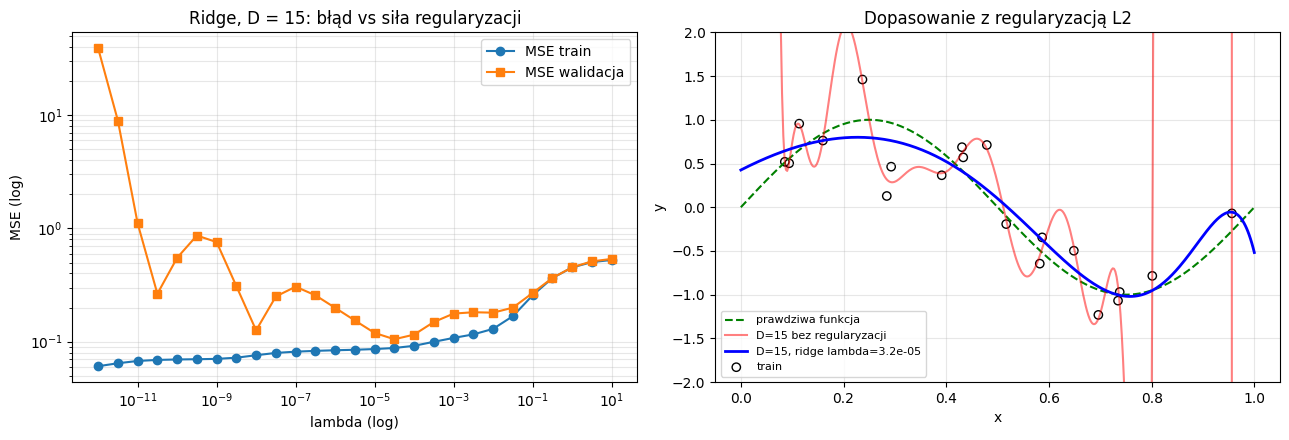

In [38]:
def dopasuj_ridge(x, y, stopien, lam):
    Phi = poly_features(x, stopien)
    n = len(x)
    # (Phi^T Phi + n*lam*I) w = Phi^T y
    A = Phi.T @ Phi + n * lam * np.eye(stopien + 1)
    # bez kary na bias
    A[0, 0] -= n * lam
    return np.linalg.solve(A, Phi.T @ y)

D_duzy = 15
lambdy = np.logspace(-12, 1, 27)
mse_tr_l, mse_va_l = [], []
for lam in lambdy:
    wl = dopasuj_ridge(x_trp, y_trp, D_duzy, lam)
    mse_tr_l.append(mse(y_trp, poly_features(x_trp, D_duzy) @ wl))
    mse_va_l.append(mse(y_vap, poly_features(x_vap, D_duzy) @ wl))
best_lam = lambdy[int(np.argmin(mse_va_l))]
print(f"najlepsza lambda = {best_lam:.2e}, MSE val = {min(mse_va_l):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogx(lambdy, mse_tr_l, "o-", label="MSE train")
ax[0].semilogx(lambdy, mse_va_l, "s-", label="MSE walidacja")
ax[0].set_yscale("log"); ax[0].set_title(f"Ridge, D = {D_duzy}: błąd vs siła regularyzacji")
ax[0].set_xlabel("lambda (log)"); ax[0].set_ylabel("MSE (log)"); ax[0].legend(); ax[0].grid(alpha=0.3, which="both")
ax[1].plot(xx, prawdziwa_f(xx), "g--", label="prawdziwa funkcja")
ax[1].plot(xx, poly_features(xx, D_duzy) @ dopasuj_wielomian(x_trp, y_trp, D_duzy), "r", alpha=0.5, label="D=15 bez regularyzacji")
ax[1].plot(xx, poly_features(xx, D_duzy) @ dopasuj_ridge(x_trp, y_trp, D_duzy, best_lam), "b", lw=2, label=f"D=15, ridge lambda={best_lam:.1e}")
ax[1].scatter(x_trp, y_trp, edgecolors="k", facecolors="none", label="train")
ax[1].set_ylim(-2, 2); ax[1].set_title("Dopasowanie z regularyzacją L2"); ax[1].set_xlabel("x"); ax[1].set_ylabel("y"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Pytania kontrolne
1. Czym różni się `tf.constant` od `tf.Variable`? Jaki jest odpowiednik zmiennej, którą da się trenować, w PyTorch?
2. Masz tensor `y_pred` o kształcie `(64, 1)` i `y` o kształcie `(64,)`. Jaki kształt będzie miało `y_pred - y` i dlaczego to groźne przy liczeniu MSE?
3. Dlaczego w pętli treningowej PyTorch musimy wywoływać `optimizer.zero_grad()` (lub `x.grad.zero_()`)? Co się stanie, jeśli o tym zapomnimy?
4. Wyjaśnij, dlaczego autograd używa trybu odwrotnego (backpropagation), a nie różnic skończonych, do trenowania sieci.
5. Co się dzieje z GD dla zbyt dużego learning rate? Jak dla straty kwadratowej wyznaczyć próg rozbieżności?
6. Podaj po dwa przykłady **parametrów** i **hiperparametrów** z dzisiejszych zajęć.
7. Jakie są zalety i wady mini-batch SGD w porównaniu z full-batch GD?
8. Dlaczego do wyboru stopnia wielomianu nie możemy użyć błędu na zbiorze treningowym? Do czego służy zbiór walidacyjny, a do czego testowy?

## Podsumowanie - co warto zapamiętać
- **Tensor** = wielowymiarowa tablica z `shape`, `dtype` i urządzeniem. Pracuj w `float32`, sprawdzaj kształty, pamiętaj o NHWC (TF) vs NCHW (PyTorch).
- **Broadcasting** jest potężny, ale `(n,) - (n,1)` daje `(n,n)` - cichy błąd.
- **Wektoryzacja** zamiast pętli Pythona przyspiesza obliczenia o rzędy wielkości; GPU dodatkowo przyspiesza duże operacje macierzowe (pamiętaj o `synchronize` przy pomiarach).
- **Autograd** (`tf.GradientTape`, `loss.backward()`) liczy gradienty regułą łańcuchową w trybie odwrotnym; w PyTorch gradienty się **akumulują** - zeruj je.
- **Gradient check** (różnice centralne, `float64`) to sposób na weryfikację ręcznych pochodnych.
- Uczenie = **dane + model + strata + optymalizator**. Pętla: forward -> strata -> gradient -> krok.
- **Learning rate**: za mały - wolno, za duży - rozbieżność; dla straty kwadratowej próg $2/\lambda_{max}$. Standaryzacja cech poprawia uwarunkowanie.
- **Mini-batch SGD**: więcej tańszych, zaszumionych kroków; standard w DL.
- **Pojemność modelu** (np. stopień wielomianu) i **regularyzacja** (L2) sterują kompromisem underfitting/overfitting; wybór na **walidacji**, ocena na **teście**.

## Do sprawozdania końcowego
Sprawozdanie końcowe obejmuje wyniki z L3-L7 i mini-projekt, więc z L1 **nic nie jest obowiązkowe**. Zachowaj jednak (przydadzą się we wstępie lub w części metodycznej mini-projektu):
- wykres wpływu learning rate z Zadania 4.1 wraz z wyznaczonym `lr_kryt` - jako przykład **zweryfikowanej hipotezy** (UGŁ_U01),
- krzywą U z Zadania 6.1 (train vs walidacja) - jako uzasadnienie, dlaczego w mini-projekcie wybierasz hiperparametry na zbiorze walidacyjnym,
- jedno zdanie o tym, jak sprawdzasz poprawność gradientów/kształtów w swoim kodzie.

## Zadanie dodatkowe (dla chętnych) - GD, momentum i Adam na funkcji Rosenbrocka
Funkcja Rosenbrocka $f(x, y) = (1 - x)^2 + 100(y - x^2)^2$ ma minimum w $(1, 1)$ leżące na dnie długiej, wąskiej, zakrzywionej doliny - to klasyczny test optymalizatorów i dobry model "źle uwarunkowanej" powierzchni straty sieci.

Zaimplementuj **samodzielnie** (bez `torch.optim`, gradient licz przez `torch.autograd`) trzy optymalizatory i narysuj ich trajektorie od punktu $(-1.5, 2)$:
1. **GD:** $\theta \leftarrow \theta - \eta g$, $\eta = 10^{-3}$.
2. **Momentum:** $v \leftarrow \beta v + g$, $\theta \leftarrow \theta - \eta v$, $\beta = 0.9$, $\eta = 2\cdot 10^{-4}$ (sprawdź też, co się dzieje dla $\eta = 10^{-3}$).
3. **Adam:** $m \leftarrow \beta_1 m + (1-\beta_1)g$, $v \leftarrow \beta_2 v + (1-\beta_2) g^2$, korekta biasu $\hat m = m/(1-\beta_1^t)$, $\hat v = v/(1-\beta_2^t)$, $\theta \leftarrow \theta - \eta\, \hat m/(\sqrt{\hat v}+\epsilon)$; $\eta = 0.02$, $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon=10^{-8}$.

Porównaj odległość od minimum po tej samej liczbie kroków. Który optymalizator najszybciej "skręca" w dolinie i dlaczego? (W3: optymalizatory.)

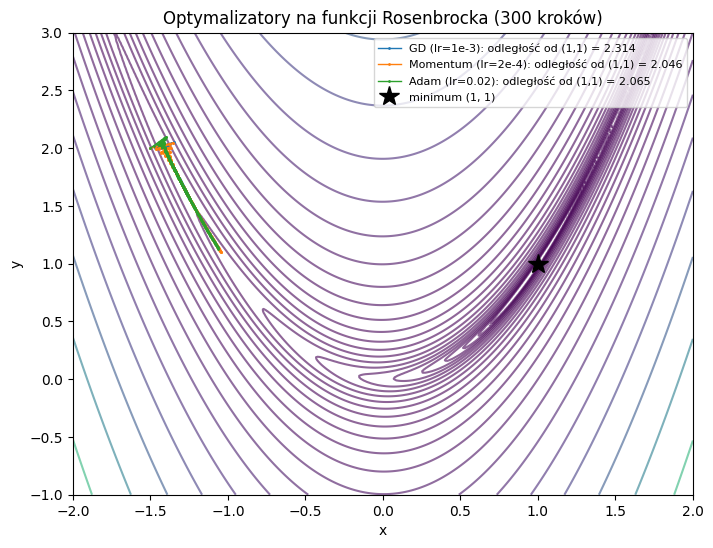

In [39]:
def rosenbrock(p):
    return (1 - p[0]) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2

KROKI_R = 300 if SZYBKI_TRYB else 3000

def optymalizuj(metoda, lr, kroki=KROKI_R, start=(-1.5, 2.0)):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    sciezka_r = [p.detach().numpy().copy()]
    m = torch.zeros(2, dtype=torch.float64)
    v = torch.zeros(2, dtype=torch.float64)
    beta1, beta2, eps = 0.9, 0.999, 1e-8
    beta_m = 0.9
    # pętla z GD / momentum / Adam
    for t in range(1, kroki + 1):
        f = rosenbrock(p)
        f.backward()
        g = p.grad.detach().clone()
        with torch.no_grad():
            if metoda == "gd":
                # GD
                p -= lr * g
            elif metoda == "momentum":
                # momentum
                v = beta_m * v + g
                p -= lr * v
            elif metoda == "adam":
                # Adam
                m = beta1 * m + (1 - beta1) * g
                v = beta2 * v + (1 - beta2) * g ** 2
                # korekta biasu
                m_hat = m / (1 - beta1 ** t)
                v_hat = v / (1 - beta2 ** t)
                p -= lr * m_hat / (torch.sqrt(v_hat) + eps)
            p.grad.zero_()
        sciezka_r.append(p.detach().numpy().copy())
    return np.array(sciezka_r)

trajektorie = {"GD (lr=1e-3)": optymalizuj("gd", 1e-3),
               "Momentum (lr=2e-4)": optymalizuj("momentum", 2e-4),
               "Adam (lr=0.02)": optymalizuj("adam", 0.02)}

Xr, Yr = np.meshgrid(np.linspace(-2, 2, 300), np.linspace(-1, 3, 300))
Zr = (1 - Xr) ** 2 + 100 * (Yr - Xr ** 2) ** 2
plt.figure(figsize=(8, 6))
plt.contour(Xr, Yr, Zr, levels=np.logspace(-1, 3.5, 25), cmap="viridis", alpha=0.6)
for nazwa, tr in trajektorie.items():
    plt.plot(tr[:, 0], tr[:, 1], ".-", ms=2, lw=1, label=f"{nazwa}: odległość od (1,1) = {np.linalg.norm(tr[-1] - 1):.3f}")
plt.plot(1, 1, "k*", ms=15, label="minimum (1, 1)")
plt.title(f"Optymalizatory na funkcji Rosenbrocka ({KROKI_R} kroków)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(fontsize=8); plt.show()